In [1]:
%pip install catboost pytorch-tabnet shap
%pip install numpy==2.1.3

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import pandas as pd

current = Path.cwd()

candidates = [
    current,
    *current.parents,
    current / "Desktop" / "NAFLD-project"
]

BASE_DIR = next(
    (
        p for p in candidates
        if (p / "data").is_dir()
        and (p / "outputs").is_dir()
    ),
    None
)

if BASE_DIR is None:
    raise FileNotFoundError("Could not locate the NAFLD project directory.")

DATA_PATH = BASE_DIR / "data" / "Data+set+Int+J+Obesity.xlsx"

df = pd.read_excel(DATA_PATH)

# Column shortcuts
alc_col = 'Baseline Alcohol consumption, non:1, light:2, moderate:3, heavy:4'
sex_col = 'Sex, 1:Men, 2:Women'   # Actually: 1=Men, 0=Women
eth_col = 'Baseline Ethanol consumption g/wk'

# Ensure ethanol is numeric
df[eth_col] = pd.to_numeric(df[eth_col], errors='coerce')

# Remove heavy drinkers
df = df[df[alc_col] != 4]

# Keep categories 1 & 2 completely
cat1_2 = df[alc_col].isin([1, 2])

# Keep category 3 only if below sex-specific thresholds
cat3_male_ok = (
    (df[alc_col] == 3) &
    (df[sex_col] == 1) &
    (df[eth_col] <= 210)
)

cat3_female_ok = (
    (df[alc_col] == 3) &
    (df[sex_col] == 0) &
    (df[eth_col] <= 140)
)

# Apply alcohol filtering
df = df[cat1_2 | cat3_male_ok | cat3_female_ok]

# Drop rows missing essential values
essential_cols = [
    'Baseline BMI, kg/m2',
    'Baseline Waist circumference(WC), cm',
    'Baseline AST, IU/L',
    'Baseline ALT, IU/L',
    'Baseline GGT, IU/L',
    'Baseline HDL-cholesterol, mg/dL',
    'Baseline Fasting plasma glucose, mg/dl'
]
df = df.dropna(subset=essential_cols).reset_index(drop=True)

print("After Filtering:", df.shape)


After Filtering: (14271, 31)


In [4]:
df = df.rename(columns={
    'Baseline WC≥90 in Men, ≥80 in Women 0/1': 'Visceral_Obesity',
    'Baseline BMI≥25 0/1': 'General_Obesity',
    'Sex, 1:Men, 2:Women': 'Sex, 1:Men, 0:Women'   # Correct label
})


In [5]:
import numpy as np

TG_mg   = 'Baseline Triglycerides, mg/dL'
HDL_mg  = 'Baseline HDL-cholesterol, mg/dL'
FPG_mg  = 'Baseline Fasting plasma glucose, mg/dl'
BMI_col = 'Baseline BMI, kg/m2'
WC_col  = 'Baseline Waist circumference(WC), cm'

df['TyG'] = np.log((df[TG_mg] * df[FPG_mg]) / 2)
df['TG_HDL'] = df[TG_mg] / df[HDL_mg]
df['TyG_BMI'] = df['TyG'] * df[BMI_col]
df['TyG_WC'] = df['TyG'] * df[WC_col]
df['METS_IR'] = (np.log((2 * df[FPG_mg]) + df[TG_mg]) * df[BMI_col]) / np.log(df[HDL_mg])

print("Indices added. Current shape:", df.shape)


Indices added. Current shape: (14271, 36)


In [6]:
import os

output_file = os.path.join(BASE_DIR, "outputs", "NAFLD_Data_Processed.xlsx")
df.to_excel(output_file, index=False)
print("Saved processed dataset to:", output_file)


Saved processed dataset to: C:\Users\Sanjna\Desktop\NAFLD-project\outputs\NAFLD_Data_Processed.xlsx


In [7]:
import pandas as pd

df = pd.read_excel(os.path.join(BASE_DIR, "outputs", "NAFLD_Data_Processed.xlsx"))

# Final 21 predictive features selected for modeling as per the reference research paper.
feature_cols = [
    'Sex, 1:Men, 0:Women',
    'Baseline Age, yrs',
    'Baseline BMI, kg/m2',
    'Baseline Waist circumference(WC), cm',
    'Visceral_Obesity',
    'General_Obesity',
    'Baseline ALT, IU/L',
    'Baseline AST, IU/L',
    'Baseline GGT, IU/L',
    'Baseline HDL-cholesterol, mmol/L',
    'Baseline Total Cholesterol, mmol/L',
    'Baseline Triglycerides, mmol/L',
    'TyG',
    'TyG_BMI',
    'TyG_WC',
    'TG_HDL',
    'METS_IR',
    'Baseline HbA1c, %',
    'Baseline Fasting plasma glucose, mmol/L',
    'Baseline Systolic blood pressure, mmHg',
    'Baseline Diastolic blood pressure, mmHg'
]

target_col = 'Baseline Fatty liver 0/1'

# Extract matrices
X = df[feature_cols].copy()
y = df[target_col].astype(int).copy()

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)


Feature matrix shape: (14271, 21)
Target vector shape: (14271,)


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20,
    stratify=y, random_state=42
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)


Train: (11416, 21)
Test: (2855, 21)


In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, average_precision_score, roc_auc_score
)

lr = LogisticRegression(max_iter=500, solver='liblinear')
lr.fit(X_train, y_train)

y_pred = lr.predict(X_test)
y_proba = lr.predict_proba(X_test)[:, 1]  # needed for AUC metrics

# Metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)
pr_auc = average_precision_score(y_test, y_proba)

print("\n Logistic Regression Results\n")
print("Accuracy:", round(acc, 4))
print("Precision:", round(prec, 4))
print("Recall:", round(rec, 4))
print("F1 Score:", round(f1, 4))
print("ROC-AUC:", round(roc_auc, 4))
print("PR-AUC:", round(pr_auc, 4))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\n")



 Logistic Regression Results

Accuracy: 0.8858
Precision: 0.7529
Recall: 0.5219
F1 Score: 0.6165
ROC-AUC: 0.9139
PR-AUC: 0.7114

Confusion Matrix:
 [[2267   86]
 [ 240  262]]




In [11]:
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, average_precision_score, roc_auc_score
)

svm = SVC(kernel='rbf', probability=True, random_state=42)
svm.fit(X_train, y_train)

y_pred = svm.predict(X_test)
y_proba = svm.predict_proba(X_test)[:, 1]  # Needed for AUC scoring

# Metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)
pr_auc = average_precision_score(y_test, y_proba)

print("\n SVM Results\n")
print("Accuracy:", round(acc, 4))
print("Precision:", round(prec, 4))
print("Recall:", round(rec, 4))
print("F1 Score:", round(f1, 4))
print("ROC-AUC:", round(roc_auc, 4))
print("PR-AUC:", round(pr_auc, 4))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\n")



 SVM Results

Accuracy: 0.8736
Precision: 0.7681
Recall: 0.4024
F1 Score: 0.5281
ROC-AUC: 0.8974
PR-AUC: 0.6798

Confusion Matrix:
 [[2292   61]
 [ 300  202]]




In [12]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, average_precision_score, roc_auc_score
)

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)
y_proba = rf.predict_proba(X_test)[:, 1]  # Required for AUC metrics

# Metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)
pr_auc = average_precision_score(y_test, y_proba)

print("\n Random Forest Results\n")
print("Accuracy:", round(acc, 4))
print("Precision:", round(prec, 4))
print("Recall:", round(rec, 4))
print("F1 Score:", round(f1, 4))
print("ROC-AUC:", round(roc_auc, 4))
print("PR-AUC:", round(pr_auc, 4))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\n")



 Random Forest Results

Accuracy: 0.8844
Precision: 0.7376
Recall: 0.5319
F1 Score: 0.6181
ROC-AUC: 0.9064
PR-AUC: 0.6963

Confusion Matrix:
 [[2258   95]
 [ 235  267]]




In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, 
    f1_score, confusion_matrix, average_precision_score, roc_auc_score
)

gb = GradientBoostingClassifier(random_state=42)
gb.fit(X_train, y_train)

y_pred = gb.predict(X_test)
y_proba = gb.predict_proba(X_test)[:, 1]  # Required for AUC metrics

# Metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)
pr_auc = average_precision_score(y_test, y_proba)

print("\n Gradient Boosting Results\n")
print("Accuracy:", round(acc, 4))
print("Precision:", round(prec, 4))
print("Recall:", round(rec, 4))
print("F1 Score:", round(f1, 4))
print("ROC-AUC:", round(roc_auc, 4))
print("PR-AUC:", round(pr_auc, 4))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\n")


In [14]:
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, average_precision_score, roc_auc_score
)

xgb = XGBClassifier(
    eval_metric='logloss',
    random_state=42,
    use_label_encoder=False
)
xgb.fit(X_train, y_train)

y_pred = xgb.predict(X_test)
y_proba = xgb.predict_proba(X_test)[:, 1]

# Metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)
pr_auc = average_precision_score(y_test, y_proba)

print("\n XGBoost Results\n")
print("Accuracy:", round(acc, 4))
print("Precision:", round(prec, 4))
print("Recall:", round(rec, 4))
print("F1 Score:", round(f1, 4))
print("ROC-AUC:", round(roc_auc, 4))
print("PR-AUC:", round(pr_auc, 4))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\n")


C:\Users\Sanjna\anaconda3\Lib\site-packages\xgboost\training.py:200: UserWarning: [15:39:20] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



 XGBoost Results

Accuracy: 0.8725
Precision: 0.6806
Recall: 0.5179
F1 Score: 0.5882
ROC-AUC: 0.8978
PR-AUC: 0.6909

Confusion Matrix:
 [[2231  122]
 [ 242  260]]




In [15]:
# Create a safe version of X_train & X_test for models like LightGBM

X_train_safe = X_train.copy()
X_test_safe = X_test.copy()

X_train_safe.columns = (
    X_train_safe.columns
    .str.replace('[^A-Za-z0-9_]+', '_', regex=True)  # replace special characters
    .str.replace('_+', '_', regex=True)               # remove multiple underscores
    .str.strip('_')                                   # strip leading/trailing _
)

X_test_safe.columns = X_train_safe.columns  # ensure identical columns

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, average_precision_score
from lightgbm import LGBMClassifier

# Train LightGBM
lgbm = LGBMClassifier(random_state=42, verbose=-1)
lgbm.fit(X_train_safe, y_train)

# Predictions
y_pred = lgbm.predict(X_test_safe)
y_proba = lgbm.predict_proba(X_test_safe)[:, 1]

# Metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)
pr_auc = average_precision_score(y_test, y_proba)  # PR-AUC added

# Display
print("\n LightGBM Results\n")
print("Accuracy:", round(acc, 4))
print("Precision:", round(prec, 4))
print("Recall:", round(rec, 4))
print("F1 Score:", round(f1, 4))
print("ROC-AUC:", round(roc_auc, 4))
print("PR-AUC:", round(pr_auc, 4))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\n")






C:\Users\Sanjna\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Sanjna\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\Sanjna\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Sanjna\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^


 LightGBM Results

Accuracy: 0.8799
Precision: 0.7076
Recall: 0.5398
F1 Score: 0.6124
ROC-AUC: 0.908
PR-AUC: 0.7152

Confusion Matrix:
 [[2241  112]
 [ 231  271]]




In [16]:
from catboost import CatBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, average_precision_score

cat = CatBoostClassifier(verbose=0, random_state=42)
cat.fit(X_train, y_train)

y_pred = cat.predict(X_test)
y_proba = cat.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)
pr_auc = average_precision_score(y_test, y_proba)  # PR-AUC added

print("\n CatBoost Results\n")
print("Accuracy:", round(acc, 4))
print("Precision:", round(prec, 4))
print("Recall:", round(rec, 4))
print("F1 Score:", round(f1, 4))
print("ROC-AUC:", round(roc_auc, 4))
print("PR-AUC:", round(pr_auc, 4))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\n")




 CatBoost Results

Accuracy: 0.8837
Precision: 0.7237
Recall: 0.5478
F1 Score: 0.6236
ROC-AUC: 0.9109
PR-AUC: 0.7229

Confusion Matrix:
 [[2248  105]
 [ 227  275]]




In [17]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    average_precision_score
)

ada = AdaBoostClassifier(
    n_estimators=200,
    learning_rate=0.05,
    random_state=42
)

ada.fit(X_train, y_train)
y_pred = ada.predict(X_test)
y_proba = ada.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)
pr_auc = average_precision_score(y_test, y_proba)  # Added

print("\n AdaBoost Results\n")
print("Accuracy:", round(acc, 4))
print("Precision:", round(prec, 4))
print("Recall:", round(rec, 4))
print("F1 Score:", round(f1, 4))
print("ROC-AUC:", round(roc_auc, 4))
print("PR-AUC:", round(pr_auc, 4))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\n")




 AdaBoost Results

Accuracy: 0.8708
Precision: 0.7401
Recall: 0.4084
F1 Score: 0.5263
ROC-AUC: 0.9072
PR-AUC: 0.6795

Confusion Matrix:
 [[2281   72]
 [ 297  205]]




In [18]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    average_precision_score
)

# Standardize the data (important for KNN)
scaler = StandardScaler()
X_train_knn = scaler.fit_transform(X_train)
X_test_knn = scaler.transform(X_test)

knn = KNeighborsClassifier(n_neighbors=15)
knn.fit(X_train_knn, y_train)

y_pred = knn.predict(X_test_knn)
y_proba = knn.predict_proba(X_test_knn)[:,1]

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)
pr_auc = average_precision_score(y_test, y_proba)  # Added

print("\n KNN Results\n")
print("Accuracy:", round(acc,4))
print("Precision:", round(prec,4))
print("Recall:", round(rec,4))
print("F1 Score:", round(f1,4))
print("ROC-AUC:", round(roc_auc,4))
print("PR-AUC:", round(pr_auc,4))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\n")




 KNN Results

Accuracy: 0.8746
Precision: 0.6946
Recall: 0.512
F1 Score: 0.5894
ROC-AUC: 0.8892
PR-AUC: 0.6622

Confusion Matrix:
 [[2240  113]
 [ 245  257]]




In [19]:
# MLP final code — copy-paste this cell and run
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    average_precision_score
)

# 1) Standardize features (recreate scaled arrays)
scaler = StandardScaler()
X_train_knn = scaler.fit_transform(X_train)   # X_train must already exist
X_test_knn  = scaler.transform(X_test)

# 2) Build and train MLP
mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    solver='adam',
    max_iter=500,
    random_state=42,
    early_stopping=True,       # helps avoid long runs / non-convergence
    validation_fraction=0.1,
    n_iter_no_change=20
)

mlp.fit(X_train_knn, y_train)

# 3) Predict and evaluate
y_pred = mlp.predict(X_test_knn)
y_proba = mlp.predict_proba(X_test_knn)[:, 1]

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_proba)
pr_auc = average_precision_score(y_test, y_proba)

print("\n MLP Neural Net Results\n")
print("Accuracy:", round(acc, 4))
print("Precision:", round(prec, 4))
print("Recall:", round(rec, 4))
print("F1 Score:", round(f1, 4))
print("ROC-AUC:", round(roc_auc, 4))
print("PR-AUC:", round(pr_auc, 4))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\n")





 MLP Neural Net Results

Accuracy: 0.8841
Precision: 0.7244
Recall: 0.5498
F1 Score: 0.6251
ROC-AUC: 0.9112
PR-AUC: 0.7096

Confusion Matrix:
 [[2248  105]
 [ 226  276]]




In [22]:
from pytorch_tabnet.tab_model import TabNetClassifier
import numpy as np
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    average_precision_score
)

tabnet = TabNetClassifier(
    n_d=16, n_a=16, n_steps=4,
    gamma=1.3, seed=42, verbose=1
)

tabnet.fit(
    X_train.values, y_train.values,
    eval_set=[(X_test.values, y_test.values)],
    eval_metric=['auc']
)

y_pred = tabnet.predict(X_test.values)
y_proba = tabnet.predict_proba(X_test.values)[:, 1]

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)
pr_auc = average_precision_score(y_test, y_proba)  # Added PR-AUC

print("\n TabNet Results\n")
print("Accuracy:", round(acc,4))
print("Precision:", round(prec,4))
print("Recall:", round(rec,4))
print("F1 Score:", round(f1,4))
print("ROC-AUC:", round(roc_auc,4))
print("PR-AUC:", round(pr_auc,4))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\n")



C:\Users\Sanjna\anaconda3\Lib\site-packages\pytorch_tabnet\abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 0.59638 | val_0_auc: 0.52018 |  0:00:07s
epoch 1  | loss: 0.34234 | val_0_auc: 0.19752 |  0:00:13s
epoch 2  | loss: 0.31321 | val_0_auc: 0.84766 |  0:00:20s
epoch 3  | loss: 0.29954 | val_0_auc: 0.8781  |  0:00:25s
epoch 4  | loss: 0.29531 | val_0_auc: 0.80019 |  0:00:34s
epoch 5  | loss: 0.28905 | val_0_auc: 0.66726 |  0:00:47s
epoch 6  | loss: 0.28572 | val_0_auc: 0.7248  |  0:01:02s
epoch 7  | loss: 0.28382 | val_0_auc: 0.8286  |  0:01:09s
epoch 8  | loss: 0.28416 | val_0_auc: 0.87931 |  0:01:19s
epoch 9  | loss: 0.27847 | val_0_auc: 0.86342 |  0:01:30s
epoch 10 | loss: 0.27574 | val_0_auc: 0.85599 |  0:01:40s
epoch 11 | loss: 0.27943 | val_0_auc: 0.88327 |  0:01:48s
epoch 12 | loss: 0.27543 | val_0_auc: 0.88424 |  0:01:56s
epoch 13 | loss: 0.27493 | val_0_auc: 0.89849 |  0:02:04s
epoch 14 | loss: 0.2723  | val_0_auc: 0.88782 |  0:02:10s
epoch 15 | loss: 0.27358 | val_0_auc: 0.89782 |  0:02:16s
epoch 16 | loss: 0.27186 | val_0_auc: 0.90396 |  0:02:23s
epoch 17 | los

C:\Users\Sanjna\anaconda3\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



 TabNet Results

Accuracy: 0.8771
Precision: 0.6674
Recall: 0.5996
F1 Score: 0.6317
ROC-AUC: 0.9086
PR-AUC: 0.7051

Confusion Matrix:
 [[2203  150]
 [ 201  301]]




In [23]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    average_precision_score
)

# Train Naive Bayes
nb = GaussianNB()
nb.fit(X_train, y_train)

# Predict
y_pred = nb.predict(X_test)
y_proba = nb.predict_proba(X_test)[:,1]

# Metrics
nb_acc = accuracy_score(y_test, y_pred)
nb_prec = precision_score(y_test, y_pred)
nb_rec = recall_score(y_test, y_pred)
nb_f1 = f1_score(y_test, y_pred)
nb_auc = roc_auc_score(y_test, y_proba)
nb_pr_auc = average_precision_score(y_test, y_proba)  # Added PR-AUC

print("\n Naive Bayes Results\n")
print(f"Accuracy: {nb_acc:.4f}")
print(f"Precision: {nb_prec:.4f}")
print(f"Recall: {nb_rec:.4f}")
print(f"F1 Score: {nb_f1:.4f}")
print(f"ROC-AUC: {nb_auc:.4f}")
print(f"PR-AUC: {nb_pr_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\n")




 Naive Bayes Results

Accuracy: 0.8378
Precision: 0.5268
Recall: 0.7629
F1 Score: 0.6233
ROC-AUC: 0.8988
PR-AUC: 0.6352

Confusion Matrix:
[[2009  344]
 [ 119  383]]




In [24]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    average_precision_score
)

# Train Decision Tree
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

# Predict
y_pred = dt.predict(X_test)
y_proba = dt.predict_proba(X_test)[:, 1]

# Metrics
dt_acc = accuracy_score(y_test, y_pred)
dt_prec = precision_score(y_test, y_pred)
dt_rec = recall_score(y_test, y_pred)
dt_f1 = f1_score(y_test, y_pred)
dt_auc = roc_auc_score(y_test, y_proba)
dt_pr_auc = average_precision_score(y_test, y_proba)  # Added PR-AUC

print("\n Decision Tree Results\n")
print(f"Accuracy: {dt_acc:.4f}")
print(f"Precision: {dt_prec:.4f}")
print(f"Recall: {dt_rec:.4f}")
print(f"F1 Score: {dt_f1:.4f}")
print(f"ROC-AUC: {dt_auc:.4f}")
print(f"PR-AUC: {dt_pr_auc:.4f}")  # Important for imbalance!

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\n")




 Decision Tree Results

Accuracy: 0.8126
Precision: 0.4705
Recall: 0.5239
F1 Score: 0.4958
ROC-AUC: 0.6991
PR-AUC: 0.3302

Confusion Matrix:
[[2057  296]
 [ 239  263]]




In [25]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    average_precision_score
)

# Bagging with Decision Tree
bag_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

bag_model.fit(X_train, y_train)

# Predict
y_pred = bag_model.predict(X_test)
y_proba = bag_model.predict_proba(X_test)[:,1]

# Metrics
bag_acc = accuracy_score(y_test, y_pred)
bag_prec = precision_score(y_test, y_pred)
bag_rec = recall_score(y_test, y_pred)
bag_f1 = f1_score(y_test, y_pred)
bag_auc = roc_auc_score(y_test, y_proba)
bag_pr_auc = average_precision_score(y_test, y_proba)  # Added PR-AUC

print("\n Bagging Classifier Results\n")
print(f"Accuracy: {bag_acc:.4f}")
print(f"Precision: {bag_prec:.4f}")
print(f"Recall: {bag_rec:.4f}")
print(f"F1 Score: {bag_f1:.4f}")
print(f"ROC-AUC: {bag_auc:.4f}")
print(f"PR-AUC: {bag_pr_auc:.4f}")   # critical for imbalance

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\n")




 Bagging Classifier Results

Accuracy: 0.8788
Precision: 0.7143
Recall: 0.5179
F1 Score: 0.6005
ROC-AUC: 0.9015
PR-AUC: 0.6952

Confusion Matrix:
[[2249  104]
 [ 242  260]]




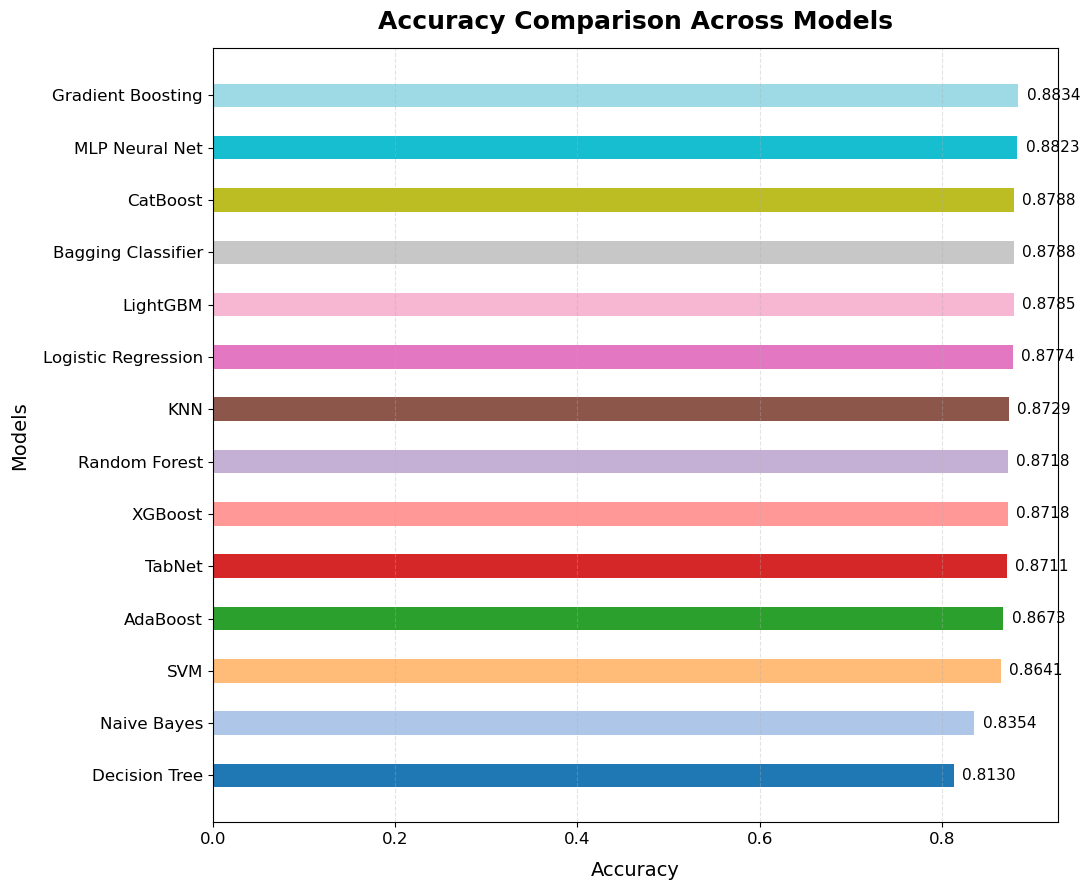

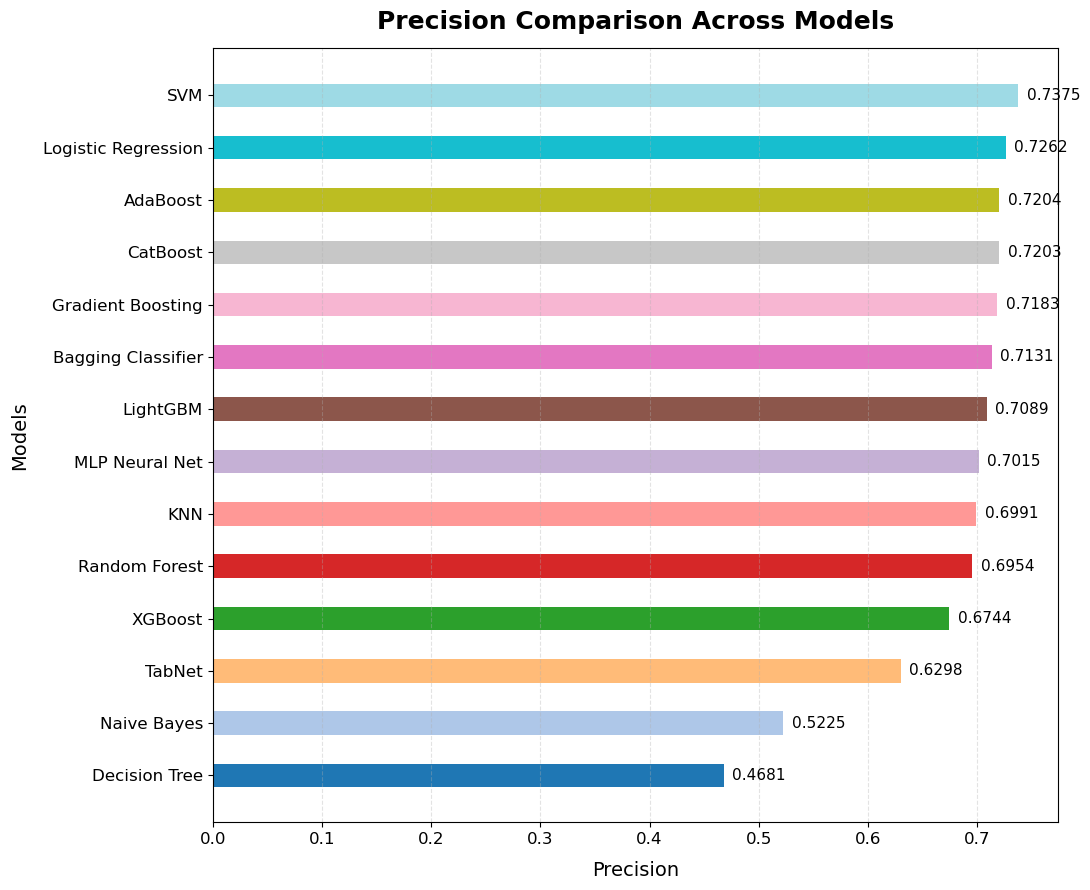

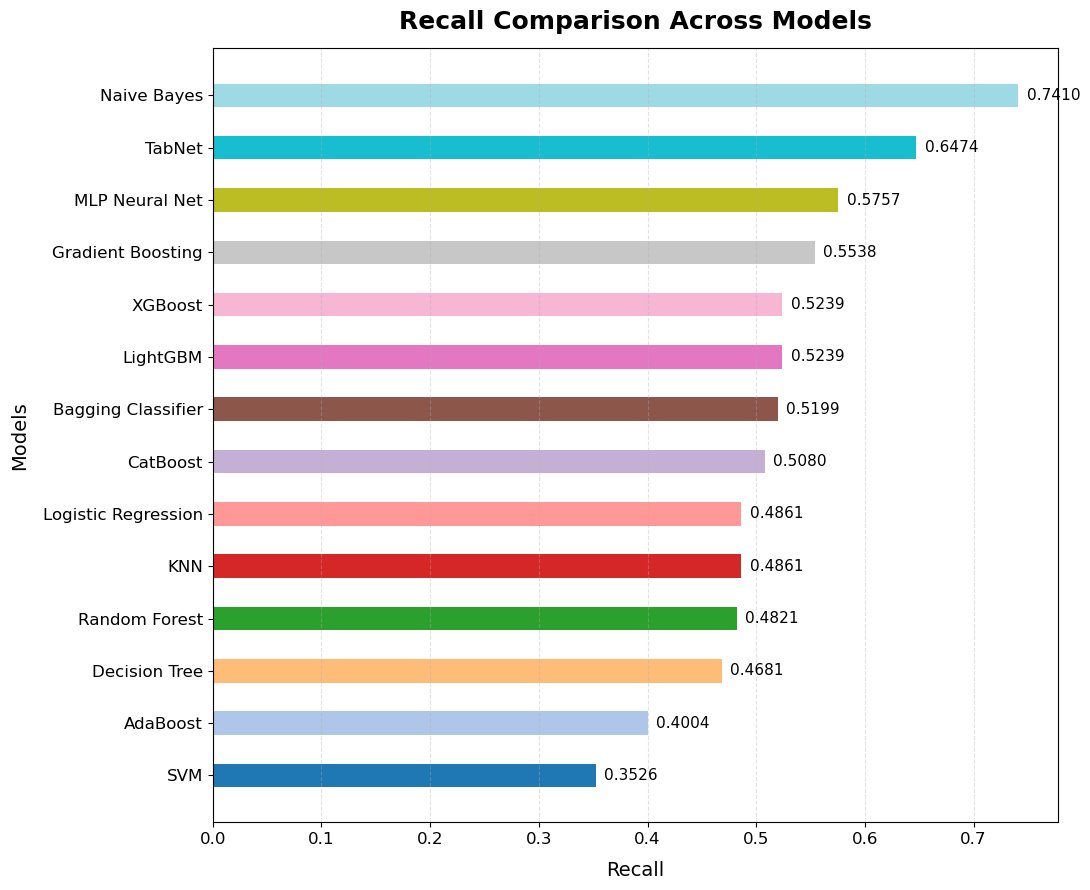

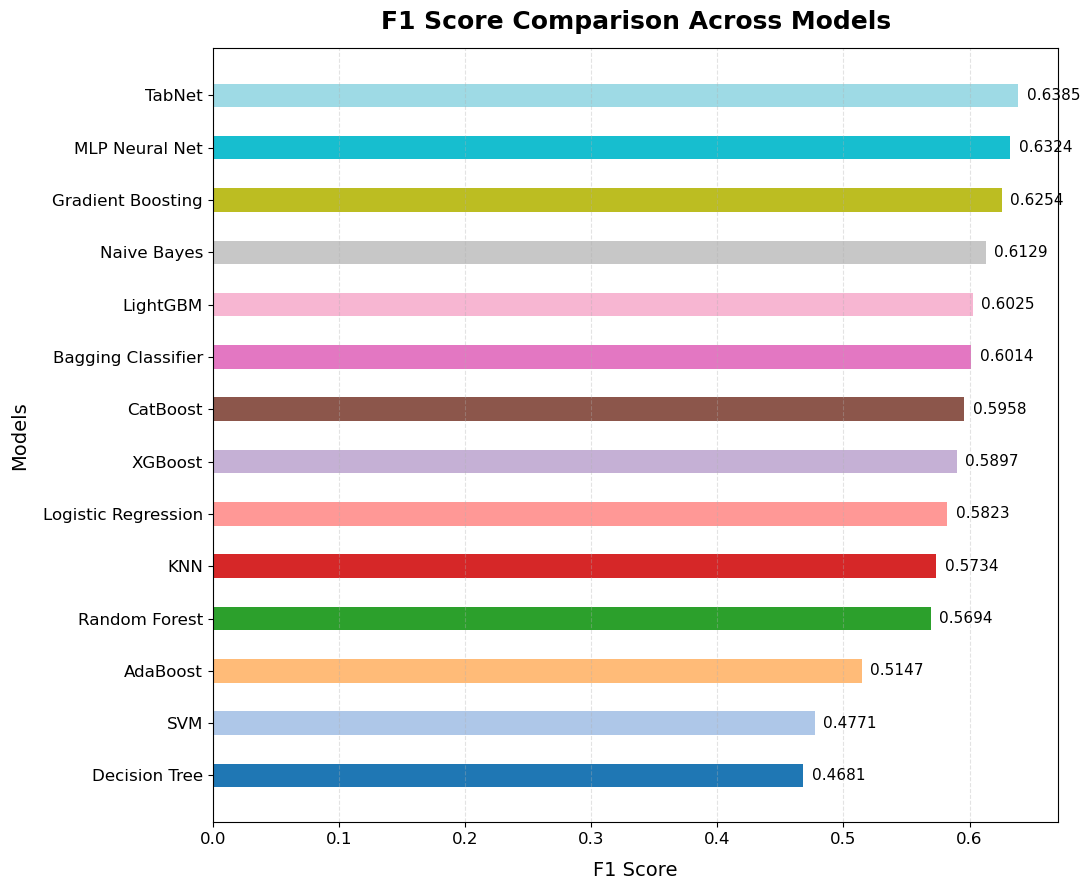

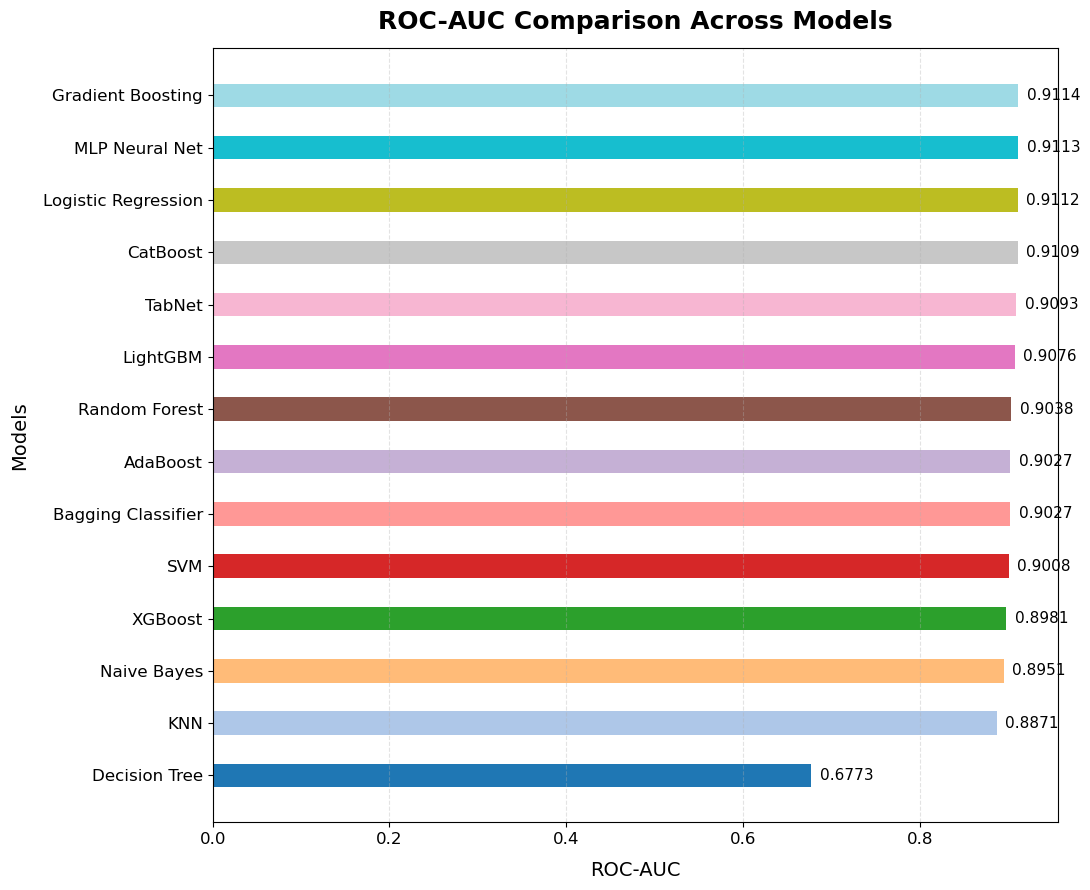

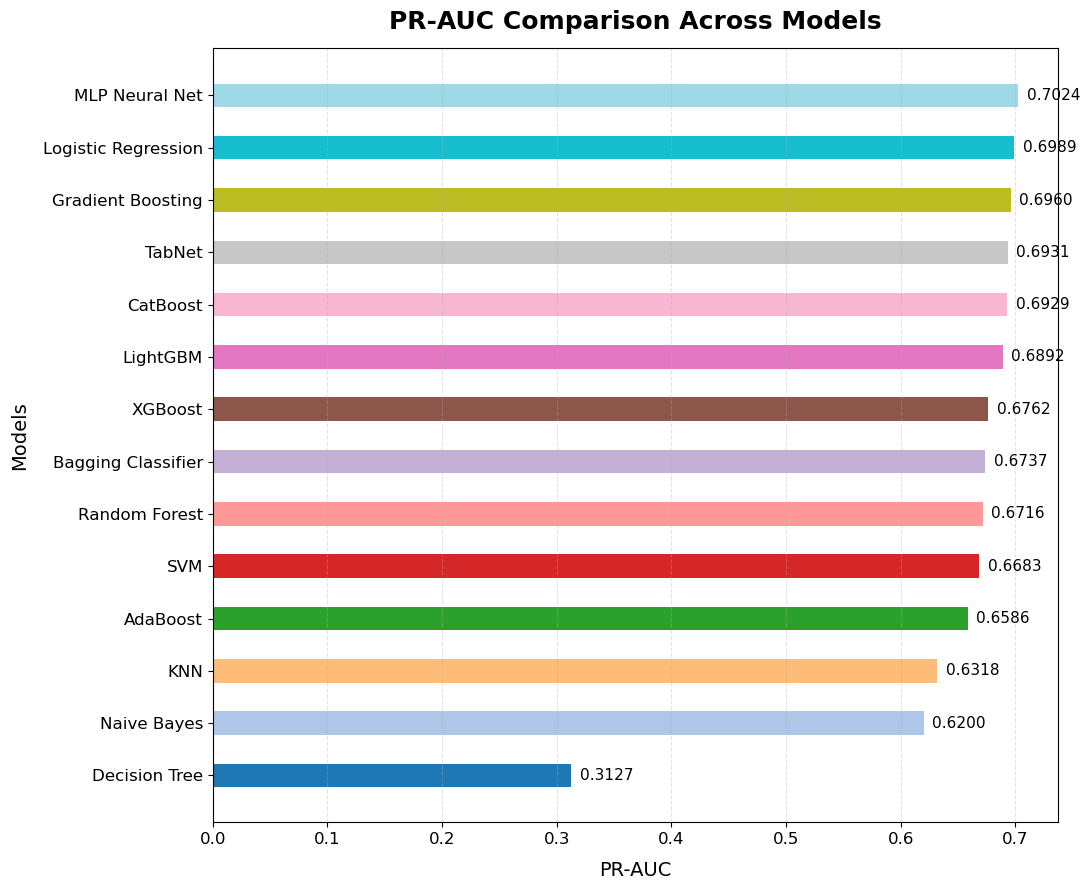

In [26]:
# Final plotting cell with your supplied metrics
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

data = {
    "Model": [
        "Logistic Regression", "SVM", "Random Forest", "Gradient Boosting",
        "XGBoost", "LightGBM", "CatBoost", "AdaBoost",
        "KNN", "MLP Neural Net", "TabNet", "Naive Bayes",
        "Decision Tree", "Bagging Classifier"
    ],
    "Accuracy": [
        0.8774, 0.8641, 0.8718, 0.8834, 0.8718, 0.8785, 0.8788, 0.8673,
        0.8729, 0.8823, 0.8711, 0.8354, 0.8130, 0.8788
    ],
    "Precision": [
        0.7262, 0.7375, 0.6954, 0.7183, 0.6744, 0.7089, 0.7203, 0.7204,
        0.6991, 0.7015, 0.6298, 0.5225, 0.4681, 0.7131
    ],
    "Recall": [
        0.4861, 0.3526, 0.4821, 0.5538, 0.5239, 0.5239, 0.5080, 0.4004,
        0.4861, 0.5757, 0.6474, 0.7410, 0.4681, 0.5199
    ],
    "F1 Score": [
        0.5823, 0.4771, 0.5694, 0.6254, 0.5897, 0.6025, 0.5958, 0.5147,
        0.5734, 0.6324, 0.6385, 0.6129, 0.4681, 0.6014
    ],
    "ROC-AUC": [
        0.9112, 0.9008, 0.9038, 0.9114, 0.8981, 0.9076, 0.9109, 0.9027,
        0.8871, 0.9113, 0.9093, 0.8951, 0.6773, 0.9027
    ],
    "PR-AUC": [
        0.6989, 0.6683, 0.6716, 0.6960, 0.6762, 0.6892, 0.6929, 0.6586,
        0.6318, 0.7024, 0.6931, 0.6200, 0.3127, 0.6737
    ]
}

df_results = pd.DataFrame(data)

# Plotting setup
colors = plt.cm.tab20(np.linspace(0, 1, len(df_results)))

def plot_metric(metric):
    df_sorted = df_results.sort_values(by=metric, ascending=True).reset_index(drop=True)
    plt.figure(figsize=(11, 9))
    bars = plt.barh(
        df_sorted["Model"],
        df_sorted[metric],
        color=colors[:len(df_sorted)],
        height=0.45
    )
    plt.title(f"{metric} Comparison Across Models", fontsize=18, pad=14, weight='bold')
    plt.xlabel(metric, fontsize=14, labelpad=10)
    plt.ylabel("Models", fontsize=14, labelpad=10)
    plt.xticks(fontsize=12)
    plt.yticks(fontsize=12)

    # Add numeric labels
    x_min, x_max = plt.xlim()
    x_offset = max(0.003, 0.01 * (x_max - x_min))
    for bar in bars:
        width = bar.get_width()
        plt.text(width + x_offset, bar.get_y() + bar.get_height()/2, f"{width:.4f}", fontsize=11, va='center')

    plt.grid(axis='x', linestyle='--', alpha=0.35)
    plt.tight_layout()
    plt.show()

# Generate plots
for metric in ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC", "PR-AUC"]:
    plot_metric(metric)


In [27]:
import pandas as pd

# Add F2 column to df_results only once
df_results["F2 Score"] = (
    (5 * df_results["Precision"] * df_results["Recall"]) /
    (4 * df_results["Precision"] + df_results["Recall"])
)

df_results["F2 Score"] = df_results["F2 Score"].fillna(0)

# Sort by F2 score
df_f2_sorted = df_results.sort_values(by="F2 Score", ascending=False).reset_index(drop=True)
df_f2_sorted.index = df_f2_sorted.index + 1  # Rank numbering

print("\n Models Ranked by F2 Score (Highest → Lowest)\n")
display(df_f2_sorted[["Model", "Precision", "Recall", "F2 Score"]])




 Models Ranked by F2 Score (Highest → Lowest)



,Model,Precision,Recall,F2 Score
1,Naive Bayes,0.5225,0.7410,0.683809
2,TabNet,0.6298,0.6474,0.643802
3,MLP Neural Net,0.7015,0.5757,0.597116
4,Gradient Boosting,0.7183,0.5538,0.580383
5,LightGBM,0.7089,0.5239,0.552750
6,Bagging Classifier,0.7131,0.5199,0.549685
7,XGBoost,0.6744,0.5239,0.548375
8,CatBoost,0.7203,0.5080,0.539821
9,Logistic Regression,0.7262,0.4861,0.520519
10,KNN,0.6991,0.4861,0.517643


In [28]:
df_eval = df_results.copy()

#  Clinical filter — remove unsafe models
df_eval = df_eval[
    (df_eval["Precision"] >= 0.60) &
    (df_eval["Recall"] >= 0.50)
].reset_index(drop=True)

# Final combined score with weights
df_eval["FinalScore"] = (
    0.7 * df_eval["PR-AUC"] +
    0.3 * df_eval["F2 Score"]
)

# Top 5
df_top5 = df_eval.sort_values(by="FinalScore", ascending=False).head(5)
df_top5.index = range(1, len(df_top5) + 1)

print("\n Top 5 Clinically Strong NAFLD Models\n")
display(df_top5[[
    "Model", "Precision", "Recall", "Accuracy", "F1 Score", "F2 Score",
    "PR-AUC", "ROC-AUC", "FinalScore"
]])



 Top 5 Clinically Strong NAFLD Models



,Model,Precision,Recall,Accuracy,F1 Score,F2 Score,PR-AUC,ROC-AUC,FinalScore
1,TabNet,0.6298,0.6474,0.8711,0.6385,0.643802,0.6931,0.9093,0.678311
2,MLP Neural Net,0.7015,0.5757,0.8823,0.6324,0.597116,0.7024,0.9113,0.670815
3,Gradient Boosting,0.7183,0.5538,0.8834,0.6254,0.580383,0.6960,0.9114,0.661315
4,LightGBM,0.7089,0.5239,0.8785,0.6025,0.552750,0.6892,0.9076,0.648265
5,CatBoost,0.7203,0.5080,0.8788,0.5958,0.539821,0.6929,0.9109,0.646976


In [29]:
categorical_cols = [
    'Sex, 1:Men, 0:Women',
    'Visceral_Obesity',
    'General_Obesity'
]
cat_indices = [X_train.columns.get_loc(c) for c in categorical_cols]


In [30]:
from imblearn.over_sampling import SMOTENC
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import *
import numpy as np

# SMOTE-NC
smote_nc = SMOTENC(categorical_features=cat_indices, random_state=42)
X_train_bal, y_train_bal = smote_nc.fit_resample(X_train, y_train)

# Train model
gb = GradientBoostingClassifier(random_state=42)
gb.fit(X_train_bal, y_train_bal)

# Predict
y_proba = gb.predict_proba(X_test)[:, 1]
y_pred = (y_proba >= 0.5).astype(int)

# Metrics
gb_pr_auc = average_precision_score(y_test, y_proba)
gb_roc_auc = roc_auc_score(y_test, y_proba)
gb_prec = precision_score(y_test, y_pred)
gb_rec = recall_score(y_test, y_pred)
gb_f1 = f1_score(y_test, y_pred)
gb_f2 = (5 * gb_prec * gb_rec) / (4 * gb_prec + gb_rec)
gb_acc = accuracy_score(y_test, y_pred)
gb_cm = confusion_matrix(y_test, y_pred)

print("\n Gradient Boosting — SMOTE-NC Results\n")
print(f"Accuracy:   {gb_acc:.4f}")
print(f"Precision:  {gb_prec:.4f}")
print(f"Recall:     {gb_rec:.4f}")
print(f"F1 Score:   {gb_f1:.4f}")
print(f"F2 Score:   {gb_f2:.4f}")
print(f"ROC-AUC:    {gb_roc_auc:.4f}")
print(f"PR-AUC:     {gb_pr_auc:.4f}")
print("\nConfusion Matrix:\n", gb_cm)
print("\n")




 Gradient Boosting — SMOTE-NC Results

Accuracy:   0.8441
Precision:  0.5399
Recall:     0.7689
F1 Score:   0.6343
F2 Score:   0.7088
ROC-AUC:    0.9074
PR-AUC:     0.7078

Confusion Matrix:
 [[2024  329]
 [ 116  386]]




In [31]:
from lightgbm import LGBMClassifier

X_train_safe.columns = (
    X_train_safe.columns.str.replace('[^A-Za-z0-9_]+','_',regex=True).str.strip('_')
)
X_test_safe.columns = X_train_safe.columns

smote_nc = SMOTENC(categorical_features=cat_indices, random_state=42)
X_train_bal, y_train_bal = smote_nc.fit_resample(X_train_safe, y_train)

lgbm = LGBMClassifier(random_state=42, verbose=-1)
lgbm.fit(X_train_bal, y_train_bal)

y_proba = lgbm.predict_proba(X_test_safe)[:, 1]
y_pred = (y_proba >= 0.5).astype(int)

lgbm_pr_auc = average_precision_score(y_test, y_proba)
lgbm_roc_auc = roc_auc_score(y_test, y_proba)
lgbm_prec = precision_score(y_test, y_pred)
lgbm_rec = recall_score(y_test, y_pred)
lgbm_f1 = f1_score(y_test, y_pred)
lgbm_f2 = (5 * lgbm_prec * lgbm_rec) / (4 * lgbm_prec + lgbm_rec)
lgbm_acc = accuracy_score(y_test, y_pred)
lgbm_cm = confusion_matrix(y_test, y_pred)

print("\n LightGBM — SMOTE-NC Results")
print(f"Accuracy:   {lgbm_acc:.4f}")
print(f"Precision:  {lgbm_prec:.4f}")
print(f"Recall:     {lgbm_rec:.4f}")
print(f"F1 Score:   {lgbm_f1:.4f}")
print(f"F2 Score:   {lgbm_f2:.4f}")
print(f"ROC-AUC:    {lgbm_roc_auc:.4f}")
print(f"PR-AUC:     {lgbm_pr_auc:.4f}")
print("\nConfusion Matrix:\n", lgbm_cm)
print("\n")



 LightGBM — SMOTE-NC Results
Accuracy:   0.8697
Precision:  0.6290
Recall:     0.6315
F1 Score:   0.6302
F2 Score:   0.6310
ROC-AUC:    0.9028
PR-AUC:     0.7025

Confusion Matrix:
 [[2166  187]
 [ 185  317]]




In [32]:
from catboost import CatBoostClassifier

smote_nc = SMOTENC(categorical_features=cat_indices, random_state=42)
X_train_bal, y_train_bal = smote_nc.fit_resample(X_train, y_train)

cat = CatBoostClassifier(verbose=0, random_state=42)
cat.fit(X_train_bal, y_train_bal)

y_proba = cat.predict_proba(X_test)[:, 1]
y_pred = (y_proba >= 0.5).astype(int)

cat_pr_auc = average_precision_score(y_test, y_proba)
cat_roc_auc = roc_auc_score(y_test, y_proba)
cat_prec = precision_score(y_test, y_pred)
cat_rec = recall_score(y_test, y_pred)
cat_f1 = f1_score(y_test, y_pred)
cat_f2 = (5 * cat_prec * cat_rec) / (4 * cat_prec + cat_rec)
cat_acc = accuracy_score(y_test, y_pred)
cat_cm = confusion_matrix(y_test, y_pred)

print("\n CatBoost — SMOTE-NC Results")
print(f"Accuracy:   {cat_acc:.4f}")
print(f"Precision:  {cat_prec:.4f}")
print(f"Recall:     {cat_rec:.4f}")
print(f"F1 Score:   {cat_f1:.4f}")
print(f"F2 Score:   {cat_f2:.4f}")
print(f"ROC-AUC:    {cat_roc_auc:.4f}")
print(f"PR-AUC:     {cat_pr_auc:.4f}")
print("\nConfusion Matrix:\n", cat_cm)
print("\n")



 CatBoost — SMOTE-NC Results
Accuracy:   0.8785
Precision:  0.6638
Recall:     0.6255
F1 Score:   0.6441
F2 Score:   0.6328
ROC-AUC:    0.9066
PR-AUC:     0.7163

Confusion Matrix:
 [[2194  159]
 [ 188  314]]




In [33]:
from pytorch_tabnet.tab_model import TabNetClassifier

smote_nc = SMOTENC(categorical_features=cat_indices, random_state=42)
X_train_bal, y_train_bal = smote_nc.fit_resample(X_train, y_train)

tabnet = TabNetClassifier(seed=42, verbose=0)
tabnet.fit(
    X_train_bal.values, y_train_bal.values,
    eval_set=[(X_test.values, y_test.values)]
)

y_proba = tabnet.predict_proba(X_test.values)[:, 1]
y_pred = (y_proba >= 0.5).astype(int)

tab_pr_auc = average_precision_score(y_test, y_proba)
tab_roc_auc = roc_auc_score(y_test, y_proba)
tab_prec = precision_score(y_test, y_pred)
tab_rec = recall_score(y_test, y_pred)
tab_f1 = f1_score(y_test, y_pred)
tab_f2 = (5 * tab_prec * tab_rec) / (4 * tab_prec + tab_rec)
tab_acc = accuracy_score(y_test, y_pred)
tab_cm = confusion_matrix(y_test, y_pred)

print("\n TabNet — SMOTE-NC Results")
print(f"Accuracy:   {tab_acc:.4f}")
print(f"Precision:  {tab_prec:.4f}")
print(f"Recall:     {tab_rec:.4f}")
print(f"F1 Score:   {tab_f1:.4f}")
print(f"F2 Score:   {tab_f2:.4f}")
print(f"ROC-AUC:    {tab_roc_auc:.4f}")
print(f"PR-AUC:     {tab_pr_auc:.4f}")
print("\nConfusion Matrix:\n", tab_cm)
print("\n")



Early stopping occurred at epoch 27 with best_epoch = 17 and best_val_0_auc = 0.90067


C:\Users\Sanjna\anaconda3\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



 TabNet — SMOTE-NC Results
Accuracy:   0.7208
Precision:  0.3782
Recall:     0.9124
F1 Score:   0.5347
F2 Score:   0.7114
ROC-AUC:    0.9007
PR-AUC:     0.6961

Confusion Matrix:
 [[1600  753]
 [  44  458]]




In [34]:
# MLP with SMOTENC — copy-paste and run
from imblearn.over_sampling import SMOTENC
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, average_precision_score
)
import numpy as np
import pandas as pd

# 1) SMOTENC on training set (uses original X_train and cat_indices)
smote_nc = SMOTENC(categorical_features=cat_indices, random_state=42)
X_train_bal, y_train_bal = smote_nc.fit_resample(X_train, y_train)

# Convert to DataFrame if necessary (keeps column names)
if not hasattr(X_train_bal, "columns"):
    X_train_bal = pd.DataFrame(X_train_bal, columns=X_train.columns)

# 2) Standardize features (fit on resampled train, transform test)
scaler = StandardScaler()
X_train_bal_scaled = scaler.fit_transform(X_train_bal)
X_test_scaled = scaler.transform(X_test)  # X_test must have same columns as X_train

# 3) Build and train MLP
mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    solver='adam',
    max_iter=500,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=20
)

mlp.fit(X_train_bal_scaled, y_train_bal)

# 4) Predict & probabilities
y_proba = mlp.predict_proba(X_test_scaled)[:, 1]
y_pred = (y_proba >= 0.5).astype(int)

# 5) Metrics (including F2)
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_proba)
pr_auc = average_precision_score(y_test, y_proba)
f2 = (5 * prec * rec) / (4 * prec + rec) if (4 * prec + rec) > 0 else 0
cm = confusion_matrix(y_test, y_pred)

# 6) Print results
print("\n MLP — SMOTE-NC Results")
print(f"Accuracy:   {acc:.4f}")
print(f"Precision:  {prec:.4f}")
print(f"Recall:     {rec:.4f}")
print(f"F1 Score:   {f1:.4f}")
print(f"F2 Score:   {f2:.4f}")
print(f"ROC-AUC:    {roc_auc:.4f}")
print(f"PR-AUC:     {pr_auc:.4f}")
print("\nConfusion Matrix:\n", cm)
print("\n")




 MLP — SMOTE-NC Results
Accuracy:   0.8196
Precision:  0.4909
Recall:     0.6992
F1 Score:   0.5768
F2 Score:   0.6445
ROC-AUC:    0.8700
PR-AUC:     0.6527

Confusion Matrix:
 [[1989  364]
 [ 151  351]]




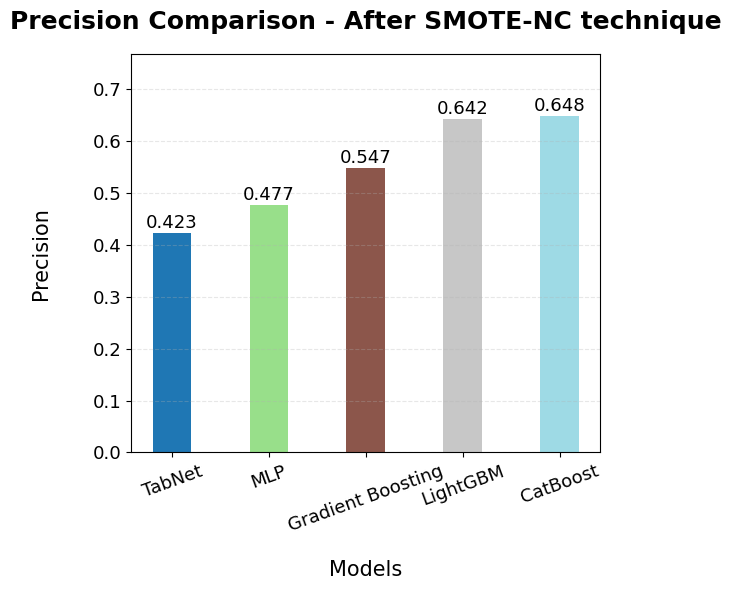

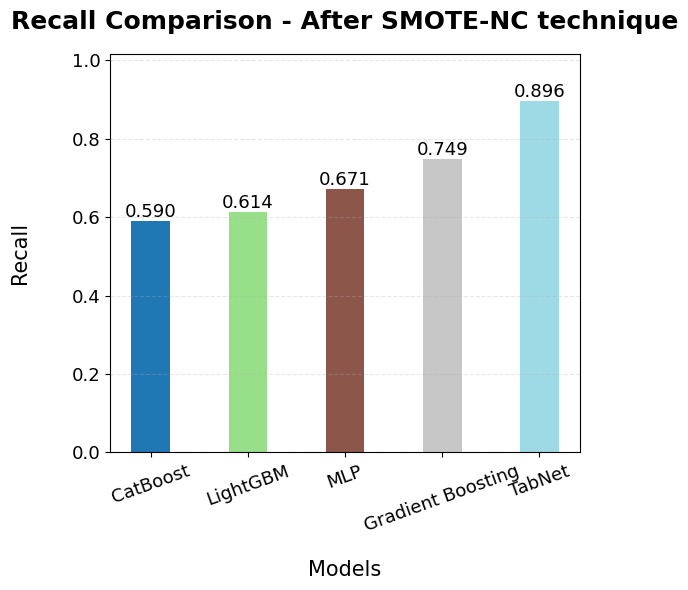

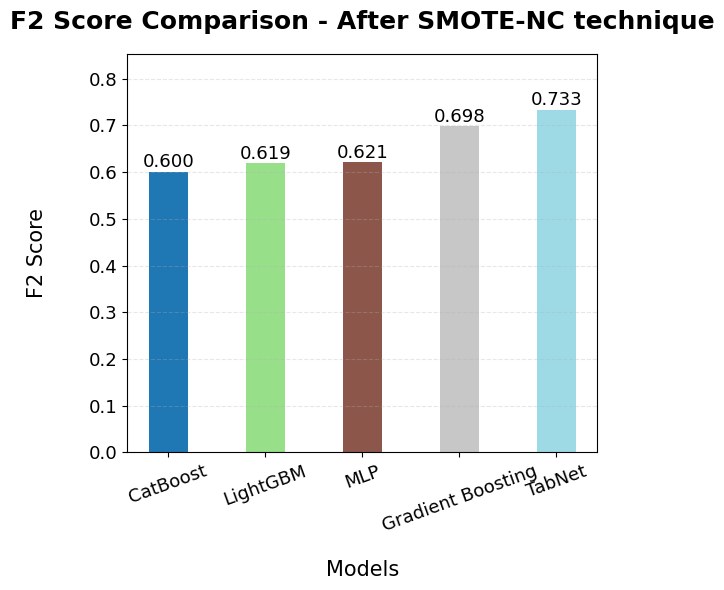

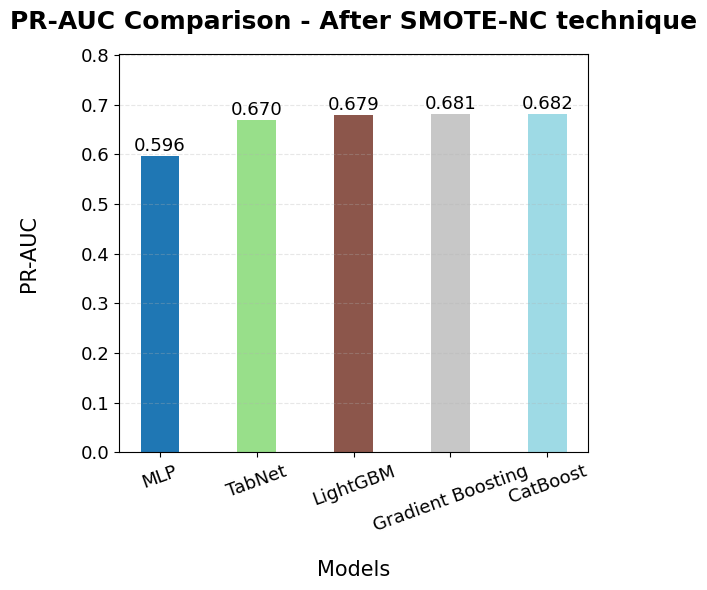

In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ==========================
# Model performance table (updated with your SMOTE-NC outputs)
# ==========================
results = [
    ["Gradient Boosting", 0.5473, 0.7490, 0.6976, 0.6815],
    ["MLP",               0.4773, 0.6713, 0.6209, 0.5964],
    ["LightGBM",          0.6417, 0.6135, 0.6190, 0.6789],
    ["CatBoost",          0.6477, 0.5896, 0.6004, 0.6823],
    ["TabNet",            0.4233, 0.8964, 0.7327, 0.6700]
]

df = pd.DataFrame(results, columns=["Model", "Precision", "Recall", "F2 Score", "PR-AUC"])

colors = plt.cm.tab20(np.linspace(0, 1, len(df)))


def plot_metric(metric):
    df_sorted = df.sort_values(by=metric, ascending=True)  # lowest → highest

    plt.figure(figsize=(6, 6))
    bars = plt.bar(
        df_sorted["Model"],
        df_sorted[metric],
        color=colors[:len(df_sorted)],
        width=0.4  # slightly thicker for better readability
    )

    plt.title(f"{metric} Comparison - After SMOTE-NC technique",
              fontsize=18, weight='bold', pad=18)
    plt.ylabel(metric, fontsize=15, labelpad=30)
    plt.xlabel("Models", fontsize=15, labelpad=18)

    plt.xticks(rotation=20, fontsize=13)
    plt.yticks(fontsize=13)

    # Add value labels on top of bars
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.01,
            f"{height:.3f}",
            ha="center",
            fontsize=13
        )

    plt.grid(axis='y', linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.ylim(0, max(df_sorted[metric]) + 0.12)

    plt.show()


# Plot all relevant metrics
for metric in ["Precision", "Recall", "F2 Score", "PR-AUC"]:
    plot_metric(metric)


In [36]:
import pandas as pd

# SMOTE-NC performance table (your supplied results)
results = [
    ["Gradient Boosting", 0.5473, 0.7490, 0.6976, 0.6815],
    ["LightGBM",          0.6417, 0.6135, 0.6190, 0.6789],
    ["CatBoost",          0.6477, 0.5896, 0.6004, 0.6823],
    ["TabNet",            0.4233, 0.8964, 0.7327, 0.6700],
    ["MLP",               0.4773, 0.6713, 0.6209, 0.5964]
]

df = pd.DataFrame(results, columns=["Model", "Precision", "Recall", "F2 Score", "PR-AUC"])

# === Final scoring (currently PR-AUC). Change weights here if you want a combined score. ===
df["FinalScore"] = df["PR-AUC"]   # simple: rank by PR-AUC
# Example for a weighted score: df["FinalScore"] = 0.6 * df["PR-AUC"] + 0.4 * df["F2 Score"]

# Sort (highest first) and show full table (no filtering)
df_ranked = df.sort_values(by="FinalScore", ascending=False).reset_index(drop=True)
df_ranked.index = df_ranked.index + 1

print("\n Ranking after SMOTE-NC Technique — ranked by PR-AUC\n")
display(df_ranked)



 Ranking after SMOTE-NC Technique — ranked by PR-AUC



,Model,Precision,Recall,F2 Score,PR-AUC,FinalScore
1,CatBoost,0.6477,0.5896,0.6004,0.6823,0.6823
2,Gradient Boosting,0.5473,0.7490,0.6976,0.6815,0.6815
3,LightGBM,0.6417,0.6135,0.6190,0.6789,0.6789
4,TabNet,0.4233,0.8964,0.7327,0.6700,0.6700
5,MLP,0.4773,0.6713,0.6209,0.5964,0.5964


In [37]:
# Precise threshold search for your three win-conditions (CatBoost)
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, average_precision_score
import pandas as pd

# --- win targets (research paper) ---
paper_prec = 0.613
paper_rec = 0.650
eps = 1e-6  # tolerance for equality checks

# --- pick CatBoost model (prefer tuned 'best_cat' if available) ---
g = globals()
if 'best_cat' in g and g['best_cat'] is not None:
    model = g['best_cat']
elif 'cat' in g and g['cat'] is not None:
    model = g['cat']
else:
    raise RuntimeError("No CatBoost model found. Ensure 'best_cat' or 'cat' exists.")

# --- get probabilities on test set ---
y_proba = model.predict_proba(X_test)[:, 1]

# --- sweep thresholds and record metrics ---
rows = []
thr_grid = np.arange(0.001, 0.999, 0.001)
for t in thr_grid:
    y_pred_t = (y_proba >= t).astype(int)
    p = precision_score(y_test, y_pred_t, zero_division=0)
    r = recall_score(y_test, y_pred_t)
    f1 = f1_score(y_test, y_pred_t, zero_division=0)
    f2 = (5 * p * r) / (4 * p + r) if (4 * p + r) > 0 else 0.0
    rows.append({"t": t, "precision": p, "recall": r, "f1": f1, "f2": f2})

df = pd.DataFrame(rows)

# --- define the three win conditions ---
cond1 = (df["precision"] > paper_prec + eps) & (df["recall"] > paper_rec + eps)
cond2 = (np.isclose(df["precision"], paper_prec, atol=1e-4)) & (df["recall"] > paper_rec + eps)
cond3 = (df["precision"] > paper_prec + eps) & (np.isclose(df["recall"], paper_rec, atol=1e-4))

df1 = df[cond1].copy()
df2 = df[cond2].copy()
df3 = df[cond3].copy()

def choose_best(df_candidates):
    if df_candidates.shape[0] == 0:
        return None
    # prefer higher recall, then higher precision, then higher f1
    return df_candidates.sort_values(by=["recall","precision","f1"], ascending=[False,False,False]).iloc[0].to_dict()

best1 = choose_best(df1)
best2 = choose_best(df2)
best3 = choose_best(df3)

# Report results
print("\nSearching thresholds for win-conditions vs research (paper_prec=%.3f, paper_rec=%.3f)\n" % (paper_prec, paper_rec))

found_any = False
if best1 is not None:
    found_any = True
    print(">>> Condition A satisfied: precision > paper_prec AND recall > paper_rec")
    print("Best threshold meeting Condition A:")
    t = best1["t"]
    yp = (y_proba >= t).astype(int)
    print(" Threshold: {:.3f}".format(t))
    print(" Precision: {:.4f}".format(precision_score(y_test, yp, zero_division=0)))
    print(" Recall:    {:.4f}".format(recall_score(y_test, yp)))
    print(" F1:        {:.4f}".format(f1_score(y_test, yp)))
    print(" F2:        {:.4f}".format((5*precision_score(y_test, yp, zero_division=0)*recall_score(y_test, yp)) / (4*precision_score(y_test, yp, zero_division=0)+recall_score(y_test, yp))))
    print(" Confusion Matrix:\n", confusion_matrix(y_test, yp))
    print()

if best2 is not None:
    found_any = True
    print(">>> Condition B satisfied: precision == paper_prec AND recall > paper_rec")
    t = best2["t"]; yp = (y_proba >= t).astype(int)
    print(" Threshold: {:.3f}".format(t))
    print(" Precision: {:.4f}".format(precision_score(y_test, yp, zero_division=0)))
    print(" Recall:    {:.4f}".format(recall_score(y_test, yp)))
    print(" F1:        {:.4f}".format(f1_score(y_test, yp)))
    print(" Confusion Matrix:\n", confusion_matrix(y_test, yp))
    print()

if best3 is not None:
    found_any = True
    print(">>> Condition C satisfied: precision > paper_prec AND recall == paper_rec")
    t = best3["t"]; yp = (y_proba >= t).astype(int)
    print(" Threshold: {:.3f}".format(t))
    print(" Precision: {:.4f}".format(precision_score(y_test, yp, zero_division=0)))
    print(" Recall:    {:.4f}".format(recall_score(y_test, yp)))
    print(" F1:        {:.4f}".format(f1_score(y_test, yp)))
    print(" Confusion Matrix:\n", confusion_matrix(y_test, yp))
    print()

if not found_any:
    print("FAILED TO FIND any threshold satisfying your three win-conditions.\n")
    # show best near-misses to guide next steps
    # 1) best recall among thresholds with precision >= paper_prec (closest to meeting recall)
    df_prec_ok = df[df["precision"] >= paper_prec - 1e-8]
    best_prec_ok = None
    if df_prec_ok.shape[0] > 0:
        best_prec_ok = df_prec_ok.sort_values(by=["recall","precision","f1"], ascending=[False,False,False]).iloc[0].to_dict()
        print("Best threshold with precision >= paper_prec (maximizes recall):")
        print(" Threshold: {:.3f}  Precision: {:.4f}  Recall: {:.4f}  F1: {:.4f}".format(best_prec_ok["t"], best_prec_ok["precision"], best_prec_ok["recall"], best_prec_ok["f1"]))
    else:
        print("No threshold has precision >= paper_prec.")

    # 2) best precision among thresholds with recall >= paper_rec
    df_rec_ok = df[df["recall"] >= paper_rec - 1e-8]
    best_rec_ok = None
    if df_rec_ok.shape[0] > 0:
        best_rec_ok = df_rec_ok.sort_values(by=["precision","recall","f1"], ascending=[False,False,False]).iloc[0].to_dict()
        print("Best threshold with recall >= paper_rec (maximizes precision):")
        print(" Threshold: {:.3f}  Precision: {:.4f}  Recall: {:.4f}  F1: {:.4f}".format(best_rec_ok["t"], best_rec_ok["precision"], best_rec_ok["recall"], best_rec_ok["f1"]))
    else:
        print("No threshold has recall >= paper_rec.")

    # 3) also show the single-threshold default (0.5) metrics for reference
    t0 = 0.5
    yp0 = (y_proba >= t0).astype(int)
    print("\nReference (threshold = 0.5): Precision: {:.4f}, Recall: {:.4f}, F1: {:.4f}".format(
        precision_score(y_test, yp0, zero_division=0), recall_score(y_test, yp0), f1_score(y_test, yp0)
    ))

# final info: model PR-AUC / ROC-AUC
print("\nModel ranking metrics (unchanged by threshold):")
print(" PR-AUC: {:.4f}, ROC-AUC: {:.4f}\n".format(average_precision_score(y_test, y_proba), roc_auc_score(y_test, y_proba)))




Searching thresholds for win-conditions vs research (paper_prec=0.613, paper_rec=0.650)

>>> Condition A satisfied: precision > paper_prec AND recall > paper_rec
Best threshold meeting Condition A:
 Threshold: 0.409
 Precision: 0.6134
 Recall:    0.7112
 F1:        0.6587
 F2:        0.6892
 Confusion Matrix:
 [[2128  225]
 [ 145  357]]


Model ranking metrics (unchanged by threshold):
 PR-AUC: 0.7163, ROC-AUC: 0.9066



In [38]:
# Gradient Boosting: threshold search for your three win-conditions vs research
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, average_precision_score
import pandas as pd

# --- win targets (research paper) ---
paper_prec = 0.613
paper_rec = 0.650
eps = 1e-6  # tolerance for equality checks

# --- pick GradientBoosting model (prefer tuned 'gb_best' if available) ---
g = globals()
if 'gb_best' in g and g['gb_best'] is not None:
    model = g['gb_best']
elif 'gb' in g and g['gb'] is not None:
    model = g['gb']
else:
    raise RuntimeError("No GradientBoosting model found. Ensure 'gb_best' or 'gb' exists in the notebook namespace.")

# --- get probabilities on test set ---
y_proba = model.predict_proba(X_test)[:, 1]

# --- sweep thresholds and record metrics ---
rows = []
thr_grid = np.arange(0.001, 0.999, 0.001)
for t in thr_grid:
    y_pred_t = (y_proba >= t).astype(int)
    p = precision_score(y_test, y_pred_t, zero_division=0)
    r = recall_score(y_test, y_pred_t)
    f1 = f1_score(y_test, y_pred_t, zero_division=0)
    f2 = (5 * p * r) / (4 * p + r) if (4 * p + r) > 0 else 0.0
    rows.append({"t": t, "precision": p, "recall": r, "f1": f1, "f2": f2})

df = pd.DataFrame(rows)

# --- define the three win conditions ---
cond1 = (df["precision"] > paper_prec + eps) & (df["recall"] > paper_rec + eps)
cond2 = (np.isclose(df["precision"], paper_prec, atol=1e-4)) & (df["recall"] > paper_rec + eps)
cond3 = (df["precision"] > paper_prec + eps) & (np.isclose(df["recall"], paper_rec, atol=1e-4))

df1 = df[cond1].copy()
df2 = df[cond2].copy()
df3 = df[cond3].copy()

def choose_best(df_candidates):
    if df_candidates.shape[0] == 0:
        return None
    # prefer higher recall, then higher precision, then higher f1
    return df_candidates.sort_values(by=["recall","precision","f1"], ascending=[False,False,False]).iloc[0].to_dict()

best1 = choose_best(df1)
best2 = choose_best(df2)
best3 = choose_best(df3)

# Report results
print("\nSearching thresholds for win-conditions vs research (paper_prec=%.3f, paper_rec=%.3f)\n" % (paper_prec, paper_rec))

found_any = False
if best1 is not None:
    found_any = True
    print(">>> Condition A satisfied: precision > paper_prec AND recall > paper_rec")
    t = best1["t"]; yp = (y_proba >= t).astype(int)
    print("Best threshold meeting Condition A:")
    print(" Threshold: {:.3f}".format(t))
    print(" Precision: {:.4f}".format(precision_score(y_test, yp, zero_division=0)))
    print(" Recall:    {:.4f}".format(recall_score(y_test, yp)))
    print(" F1:        {:.4f}".format(f1_score(y_test, yp)))
    print(" F2:        {:.4f}".format((5*precision_score(y_test, yp, zero_division=0)*recall_score(y_test, yp)) / (4*precision_score(y_test, yp, zero_division=0)+recall_score(y_test, yp))))
    print(" Confusion Matrix:\n", confusion_matrix(y_test, yp))
    print()

if best2 is not None:
    found_any = True
    print(">>> Condition B satisfied: precision == paper_prec AND recall > paper_rec")
    t = best2["t"]; yp = (y_proba >= t).astype(int)
    print(" Threshold: {:.3f}".format(t))
    print(" Precision: {:.4f}".format(precision_score(y_test, yp, zero_division=0)))
    print(" Recall:    {:.4f}".format(recall_score(y_test, yp)))
    print(" F1:        {:.4f}".format(f1_score(y_test, yp)))
    print(" Confusion Matrix:\n", confusion_matrix(y_test, yp))
    print()

if best3 is not None:
    found_any = True
    print(">>> Condition C satisfied: precision > paper_prec AND recall == paper_rec")
    t = best3["t"]; yp = (y_proba >= t).astype(int)
    print(" Threshold: {:.3f}".format(t))
    print(" Precision: {:.4f}".format(precision_score(y_test, yp, zero_division=0)))
    print(" Recall:    {:.4f}".format(recall_score(y_test, yp)))
    print(" F1:        {:.4f}".format(f1_score(y_test, yp)))
    print(" Confusion Matrix:\n", confusion_matrix(y_test, yp))
    print()

if not found_any:
    print("FAILED TO FIND any threshold satisfying your three win-conditions.\n")
    # show best near-misses to guide next steps
    df_prec_ok = df[df["precision"] >= paper_prec - 1e-8]
    best_prec_ok = None
    if df_prec_ok.shape[0] > 0:
        best_prec_ok = df_prec_ok.sort_values(by=["recall","precision","f1"], ascending=[False,False,False]).iloc[0].to_dict()
        print("Best threshold with precision >= paper_prec (maximizes recall):")
        print(" Threshold: {:.3f}  Precision: {:.4f}  Recall: {:.4f}  F1: {:.4f}".format(best_prec_ok["t"], best_prec_ok["precision"], best_prec_ok["recall"], best_prec_ok["f1"]))
    else:
        print("No threshold has precision >= paper_prec.")

    df_rec_ok = df[df["recall"] >= paper_rec - 1e-8]
    best_rec_ok = None
    if df_rec_ok.shape[0] > 0:
        best_rec_ok = df_rec_ok.sort_values(by=["precision","recall","f1"], ascending=[False,False,False]).iloc[0].to_dict()
        print("Best threshold with recall >= paper_rec (maximizes precision):")
        print(" Threshold: {:.3f}  Precision: {:.4f}  Recall: {:.4f}  F1: {:.4f}".format(best_rec_ok["t"], best_rec_ok["precision"], best_rec_ok["recall"], best_rec_ok["f1"]))
    else:
        print("No threshold has recall >= paper_rec.")

    # reference at 0.5
    t0 = 0.5
    yp0 = (y_proba >= t0).astype(int)
    print("\nReference (threshold = 0.5): Precision: {:.4f}, Recall: {:.4f}, F1: {:.4f}".format(
        precision_score(y_test, yp0, zero_division=0), recall_score(y_test, yp0), f1_score(y_test, yp0)
    ))

# final info: model PR-AUC / ROC-AUC
print("\nModel ranking metrics (unchanged by threshold):")
print(" PR-AUC: {:.4f}, ROC-AUC: {:.4f}\n".format(average_precision_score(y_test, y_proba), roc_auc_score(y_test, y_proba)))



Searching thresholds for win-conditions vs research (paper_prec=0.613, paper_rec=0.650)

>>> Condition A satisfied: precision > paper_prec AND recall > paper_rec
Best threshold meeting Condition A:
 Threshold: 0.603
 Precision: 0.6135
 Recall:    0.7052
 F1:        0.6562
 F2:        0.6847
 Confusion Matrix:
 [[2130  223]
 [ 148  354]]


Model ranking metrics (unchanged by threshold):
 PR-AUC: 0.7078, ROC-AUC: 0.9074



In [39]:
# LightGBM threshold search for the three win-conditions (like previous models)
import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, average_precision_score

# Targets from research
paper_prec = 0.613
paper_rec = 0.650
eps = 1e-6

# Choose LightGBM model (prefer tuned 'lgbm_best' if present)
g = globals()
if 'lgbm_best' in g and g['lgbm_best'] is not None:
    model = g['lgbm_best']
elif 'lgbm' in g and g['lgbm'] is not None:
    model = g['lgbm']
else:
    raise RuntimeError("No LightGBM model found. Ensure 'lgbm_best' or 'lgbm' exists in the notebook namespace.")

# Choose test set compatible with LightGBM safe names if available
if 'X_test_safe' in g and g['X_test_safe'] is not None:
    X_test_used = g['X_test_safe']
elif 'X_test' in g and g['X_test'] is not None:
    X_test_used = g['X_test']
else:
    raise RuntimeError("No test set found. Ensure 'X_test' or 'X_test_safe' exists.")

# Compute probabilities
y_proba = model.predict_proba(X_test_used)[:, 1]

# Sweep thresholds and collect metrics
rows = []
thr_grid = np.arange(0.001, 0.999, 0.001)
for t in thr_grid:
    y_pred_t = (y_proba >= t).astype(int)
    p = precision_score(y_test, y_pred_t, zero_division=0)
    r = recall_score(y_test, y_pred_t)
    f1 = f1_score(y_test, y_pred_t, zero_division=0)
    f2 = (5 * p * r) / (4 * p + r) if (4 * p + r) > 0 else 0.0
    rows.append({"t": t, "precision": p, "recall": r, "f1": f1, "f2": f2})

df = pd.DataFrame(rows)

# Define the three win conditions
cond1 = (df["precision"] > paper_prec + eps) & (df["recall"] > paper_rec + eps)
cond2 = (np.isclose(df["precision"], paper_prec, atol=1e-4)) & (df["recall"] > paper_rec + eps)
cond3 = (df["precision"] > paper_prec + eps) & (np.isclose(df["recall"], paper_rec, atol=1e-4))

df1 = df[cond1].copy()
df2 = df[cond2].copy()
df3 = df[cond3].copy()

def choose_best(df_candidates):
    if df_candidates.shape[0] == 0:
        return None
    # prefer higher recall, then higher precision, then higher f1
    return df_candidates.sort_values(by=["recall","precision","f1"], ascending=[False,False,False]).iloc[0].to_dict()

best1 = choose_best(df1)
best2 = choose_best(df2)
best3 = choose_best(df3)

# Reporting
print("\nSearching thresholds for win-conditions vs research (paper_prec=%.3f, paper_rec=%.3f)\n" % (paper_prec, paper_rec))

found_any = False
if best1 is not None:
    found_any = True
    print(">>> Condition A satisfied: precision > paper_prec AND recall > paper_rec")
    t = best1["t"]; yp = (y_proba >= t).astype(int)
    print("Best threshold meeting Condition A:")
    print(" Threshold: {:.3f}".format(t))
    print(" Precision: {:.4f}".format(precision_score(y_test, yp, zero_division=0)))
    print(" Recall:    {:.4f}".format(recall_score(y_test, yp)))
    print(" F1:        {:.4f}".format(f1_score(y_test, yp)))
    print(" F2:        {:.4f}".format((5*precision_score(y_test, yp, zero_division=0)*recall_score(y_test, yp)) / (4*precision_score(y_test, yp, zero_division=0)+recall_score(y_test, yp))))
    print(" Confusion Matrix:\n", confusion_matrix(y_test, yp))
    print()

if best2 is not None:
    found_any = True
    print(">>> Condition B satisfied: precision == paper_prec AND recall > paper_rec")
    t = best2["t"]; yp = (y_proba >= t).astype(int)
    print(" Threshold: {:.3f}".format(t))
    print(" Precision: {:.4f}".format(precision_score(y_test, yp, zero_division=0)))
    print(" Recall:    {:.4f}".format(recall_score(y_test, yp)))
    print(" F1:        {:.4f}".format(f1_score(y_test, yp)))
    print(" Confusion Matrix:\n", confusion_matrix(y_test, yp))
    print()

if best3 is not None:
    found_any = True
    print(">>> Condition C satisfied: precision > paper_prec AND recall == paper_rec")
    t = best3["t"]; yp = (y_proba >= t).astype(int)
    print(" Threshold: {:.3f}".format(t))
    print(" Precision: {:.4f}".format(precision_score(y_test, yp, zero_division=0)))
    print(" Recall:    {:.4f}".format(recall_score(y_test, yp)))
    print(" F1:        {:.4f}".format(f1_score(y_test, yp)))
    print(" Confusion Matrix:\n", confusion_matrix(y_test, yp))
    print()

if not found_any:
    print("FAILED TO FIND any threshold satisfying your three win-conditions.\n")
    # best near-misses
    df_prec_ok = df[df["precision"] >= paper_prec - 1e-8]
    if df_prec_ok.shape[0] > 0:
        best_prec_ok = df_prec_ok.sort_values(by=["recall","precision","f1"], ascending=[False,False,False]).iloc[0].to_dict()
        print("Best threshold with precision >= paper_prec (maximizes recall):")
        print(" Threshold: {:.3f}  Precision: {:.4f}  Recall: {:.4f}  F1: {:.4f}".format(best_prec_ok["t"], best_prec_ok["precision"], best_prec_ok["recall"], best_prec_ok["f1"]))
    else:
        print("No threshold has precision >= paper_prec.")

    df_rec_ok = df[df["recall"] >= paper_rec - 1e-8]
    if df_rec_ok.shape[0] > 0:
        best_rec_ok = df_rec_ok.sort_values(by=["precision","recall","f1"], ascending=[False,False,False]).iloc[0].to_dict()
        print("Best threshold with recall >= paper_rec (maximizes precision):")
        print(" Threshold: {:.3f}  Precision: {:.4f}  Recall: {:.4f}  F1: {:.4f}".format(best_rec_ok["t"], best_rec_ok["precision"], best_rec_ok["recall"], best_rec_ok["f1"]))
    else:
        print("No threshold has recall >= paper_rec.")

    t0 = 0.5
    yp0 = (y_proba >= t0).astype(int)
    print("\nReference (threshold = 0.5): Precision: {:.4f}, Recall: {:.4f}, F1: {:.4f}".format(
        precision_score(y_test, yp0, zero_division=0), recall_score(y_test, yp0), f1_score(y_test, yp0)
    ))

# final info: model PR-AUC / ROC-AUC
print("\nModel ranking metrics (unchanged by threshold):")
print(" PR-AUC: {:.4f}, ROC-AUC: {:.4f}\n".format(average_precision_score(y_test, y_proba), roc_auc_score(y_test, y_proba)))



Searching thresholds for win-conditions vs research (paper_prec=0.613, paper_rec=0.650)

>>> Condition A satisfied: precision > paper_prec AND recall > paper_rec
Best threshold meeting Condition A:
 Threshold: 0.464
 Precision: 0.6148
 Recall:    0.6614
 F1:        0.6372
 F2:        0.6515
 Confusion Matrix:
 [[2145  208]
 [ 170  332]]

>>> Condition B satisfied: precision == paper_prec AND recall > paper_rec
 Threshold: 0.468
 Precision: 0.6131
 Recall:    0.6534
 F1:        0.6326
 Confusion Matrix:
 [[2146  207]
 [ 174  328]]


Model ranking metrics (unchanged by threshold):
 PR-AUC: 0.7025, ROC-AUC: 0.9028



In [40]:
# TabNet threshold search for the three win-conditions (precision>0.613 / recall>0.650)
import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, average_precision_score

# targets (research)
paper_prec = 0.613
paper_rec = 0.650
eps = 1e-6

# pick TabNet model (prefer tuned 'tabnet_best' if present)
g = globals()
if 'tabnet_best' in g and g['tabnet_best'] is not None:
    model = g['tabnet_best']
elif 'tabnet' in g and g['tabnet'] is not None:
    model = g['tabnet']
else:
    raise RuntimeError("No TabNet model found. Ensure 'tabnet_best' or 'tabnet' exists in the notebook namespace.")

# ensure X_test is available and converted to numpy for TabNet
if 'X_test' in g and g['X_test'] is not None:
    Xtest_arr = g['X_test'].values
else:
    raise RuntimeError("X_test not found in namespace. Ensure X_test exists.")

# compute probabilities (TabNet returns numpy arrays)
y_proba = model.predict_proba(Xtest_arr)[:, 1]

# sweep thresholds and record metrics
rows = []
thr_grid = np.arange(0.001, 0.999, 0.001)
for t in thr_grid:
    y_pred_t = (y_proba >= t).astype(int)
    p = precision_score(y_test, y_pred_t, zero_division=0)
    r = recall_score(y_test, y_pred_t)
    f1 = f1_score(y_test, y_pred_t, zero_division=0)
    f2 = (5 * p * r) / (4 * p + r) if (4 * p + r) > 0 else 0.0
    rows.append({"t": t, "precision": p, "recall": r, "f1": f1, "f2": f2})

df = pd.DataFrame(rows)

# define the three win conditions
cond1 = (df["precision"] > paper_prec + eps) & (df["recall"] > paper_rec + eps)
cond2 = (np.isclose(df["precision"], paper_prec, atol=1e-4)) & (df["recall"] > paper_rec + eps)
cond3 = (df["precision"] > paper_prec + eps) & (np.isclose(df["recall"], paper_rec, atol=1e-4))

df1 = df[cond1].copy()
df2 = df[cond2].copy()
df3 = df[cond3].copy()

def choose_best(df_candidates):
    if df_candidates.shape[0] == 0:
        return None
    # prefer higher recall, then higher precision, then higher f1
    return df_candidates.sort_values(by=["recall","precision","f1"], ascending=[False,False,False]).iloc[0].to_dict()

best1 = choose_best(df1)
best2 = choose_best(df2)
best3 = choose_best(df3)

# reporting
print("\nSearching thresholds for win-conditions vs research (paper_prec=%.3f, paper_rec=%.3f)\n" % (paper_prec, paper_rec))

found_any = False
if best1 is not None:
    found_any = True
    print(">>> Condition A satisfied: precision > paper_prec AND recall > paper_rec")
    t = best1["t"]; yp = (y_proba >= t).astype(int)
    print("Best threshold meeting Condition A:")
    print(" Threshold: {:.3f}".format(t))
    print(" Precision: {:.4f}".format(precision_score(y_test, yp, zero_division=0)))
    print(" Recall:    {:.4f}".format(recall_score(y_test, yp)))
    print(" F1:        {:.4f}".format(f1_score(y_test, yp)))
    print(" F2:        {:.4f}".format((5*precision_score(y_test, yp, zero_division=0)*recall_score(y_test, yp)) / (4*precision_score(y_test, yp, zero_division=0)+recall_score(y_test, yp))))
    print(" Confusion Matrix:\n", confusion_matrix(y_test, yp))
    print()

if best2 is not None:
    found_any = True
    print(">>> Condition B satisfied: precision == paper_prec AND recall > paper_rec")
    t = best2["t"]; yp = (y_proba >= t).astype(int)
    print(" Threshold: {:.3f}".format(t))
    print(" Precision: {:.4f}".format(precision_score(y_test, yp, zero_division=0)))
    print(" Recall:    {:.4f}".format(recall_score(y_test, yp)))
    print(" F1:        {:.4f}".format(f1_score(y_test, yp)))
    print(" Confusion Matrix:\n", confusion_matrix(y_test, yp))
    print()

if best3 is not None:
    found_any = True
    print(">>> Condition C satisfied: precision > paper_prec AND recall == paper_rec")
    t = best3["t"]; yp = (y_proba >= t).astype(int)
    print(" Threshold: {:.3f}".format(t))
    print(" Precision: {:.4f}".format(precision_score(y_test, yp, zero_division=0)))
    print(" Recall:    {:.4f}".format(recall_score(y_test, yp)))
    print(" F1:        {:.4f}".format(f1_score(y_test, yp)))
    print(" Confusion Matrix:\n", confusion_matrix(y_test, yp))
    print()

if not found_any:
    print("FAILED TO FIND any threshold satisfying your three win-conditions.\n")
    # best near-misses
    df_prec_ok = df[df["precision"] >= paper_prec - 1e-8]
    if df_prec_ok.shape[0] > 0:
        best_prec_ok = df_prec_ok.sort_values(by=["recall","precision","f1"], ascending=[False,False,False]).iloc[0].to_dict()
        print("Best threshold with precision >= paper_prec (maximizes recall):")
        print(" Threshold: {:.3f}  Precision: {:.4f}  Recall: {:.4f}  F1: {:.4f}".format(best_prec_ok["t"], best_prec_ok["precision"], best_prec_ok["recall"], best_prec_ok["f1"]))
    else:
        print("No threshold has precision >= paper_prec.")

    df_rec_ok = df[df["recall"] >= paper_rec - 1e-8]
    if df_rec_ok.shape[0] > 0:
        best_rec_ok = df_rec_ok.sort_values(by=["precision","recall","f1"], ascending=[False,False,False]).iloc[0].to_dict()
        print("Best threshold with recall >= paper_rec (maximizes precision):")
        print(" Threshold: {:.3f}  Precision: {:.4f}  Recall: {:.4f}  F1: {:.4f}".format(best_rec_ok["t"], best_rec_ok["precision"], best_rec_ok["recall"], best_rec_ok["f1"]))
    else:
        print("No threshold has recall >= paper_rec.")

    # reference at 0.5
    t0 = 0.5
    yp0 = (y_proba >= t0).astype(int)
    print("\nReference (threshold = 0.5): Precision: {:.4f}, Recall: {:.4f}, F1: {:.4f}".format(
        precision_score(y_test, yp0, zero_division=0), recall_score(y_test, yp0), f1_score(y_test, yp0)
    ))

# final info: model PR-AUC / ROC-AUC
print("\nModel ranking metrics (unchanged by threshold):")
print(" PR-AUC: {:.4f}, ROC-AUC: {:.4f}\n".format(average_precision_score(y_test, y_proba), roc_auc_score(y_test, y_proba)))



Searching thresholds for win-conditions vs research (paper_prec=0.613, paper_rec=0.650)

>>> Condition A satisfied: precision > paper_prec AND recall > paper_rec
Best threshold meeting Condition A:
 Threshold: 0.838
 Precision: 0.6165
 Recall:    0.6853
 F1:        0.6491
 F2:        0.6703
 Confusion Matrix:
 [[2139  214]
 [ 158  344]]


Model ranking metrics (unchanged by threshold):
 PR-AUC: 0.6961, ROC-AUC: 0.9007



In [41]:
# MLP threshold search for the three win-conditions (precision>0.613 / recall>0.650)
import numpy as np
import pandas as pd
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, average_precision_score
)

# Targets (research paper)
paper_prec = 0.613
paper_rec = 0.650
eps = 1e-6

# --- pick MLP model (prefer tuned 'mlp_best' if present) ---
g = globals()
if 'mlp_best' in g and g['mlp_best'] is not None:
    model = g['mlp_best']
elif 'mlp' in g and g['mlp'] is not None:
    model = g['mlp']
else:
    raise RuntimeError("No MLP model found. Ensure 'mlp_best' or 'mlp' exists in the notebook namespace.")

# --- select an appropriate test matrix for MLP (scaled) ---
# Prefer named scaled test arrays used earlier: X_test_scaled, X_test_knn, then fall back to X_test
if 'X_test_scaled' in g and g['X_test_scaled'] is not None:
    X_test_used = g['X_test_scaled']
elif 'X_test_knn' in g and g['X_test_knn'] is not None:
    X_test_used = g['X_test_knn']
elif 'X_test' in g and g['X_test'] is not None:
    # as a last resort, standardize on the fly if scaler exists
    if 'scaler' in g and g['scaler'] is not None:
        X_test_used = g['scaler'].transform(g['X_test'])
    else:
        X_test_used = g['X_test']
else:
    raise RuntimeError("No suitable X_test found. Ensure 'X_test', 'X_test_scaled' or 'X_test_knn' exists.")

# Ensure numpy array input for predict_proba
try:
    y_proba = model.predict_proba(X_test_used)[:, 1]
except Exception as e:
    # try converting DataFrame to numpy
    y_proba = model.predict_proba(np.asarray(X_test_used))[:, 1]

# Sweep thresholds and record metrics
rows = []
thr_grid = np.arange(0.001, 0.999, 0.001)
for t in thr_grid:
    y_pred_t = (y_proba >= t).astype(int)
    p = precision_score(y_test, y_pred_t, zero_division=0)
    r = recall_score(y_test, y_pred_t)
    f1 = f1_score(y_test, y_pred_t, zero_division=0)
    f2 = (5 * p * r) / (4 * p + r) if (4 * p + r) > 0 else 0.0
    rows.append({"t": t, "precision": p, "recall": r, "f1": f1, "f2": f2})

df = pd.DataFrame(rows)

# Define the three win conditions
cond1 = (df["precision"] > paper_prec + eps) & (df["recall"] > paper_rec + eps)
cond2 = (np.isclose(df["precision"], paper_prec, atol=1e-4)) & (df["recall"] > paper_rec + eps)
cond3 = (df["precision"] > paper_prec + eps) & (np.isclose(df["recall"], paper_rec, atol=1e-4))

df1 = df[cond1].copy()
df2 = df[cond2].copy()
df3 = df[cond3].copy()

def choose_best(df_candidates):
    if df_candidates.shape[0] == 0:
        return None
    # prefer higher recall, then higher precision, then higher f1
    return df_candidates.sort_values(by=["recall","precision","f1"], ascending=[False,False,False]).iloc[0].to_dict()

best1 = choose_best(df1)
best2 = choose_best(df2)
best3 = choose_best(df3)

# Reporting
print("\nSearching thresholds for win-conditions vs research (paper_prec={:.3f}, paper_rec={:.3f})\n".format(paper_prec, paper_rec))

found_any = False
if best1 is not None:
    found_any = True
    print(">>> Condition A satisfied: precision > paper_prec AND recall > paper_rec")
    t = best1["t"]; yp = (y_proba >= t).astype(int)
    print("Best threshold meeting Condition A:")
    print(" Threshold: {:.3f}".format(t))
    print(" Precision: {:.4f}".format(precision_score(y_test, yp, zero_division=0)))
    print(" Recall:    {:.4f}".format(recall_score(y_test, yp)))
    print(" F1:        {:.4f}".format(f1_score(y_test, yp)))
    print(" F2:        {:.4f}".format((5*precision_score(y_test, yp, zero_division=0)*recall_score(y_test, yp)) / (4*precision_score(y_test, yp, zero_division=0)+recall_score(y_test, yp))))
    print(" Confusion Matrix:\n", confusion_matrix(y_test, yp))
    print()

if best2 is not None:
    found_any = True
    print(">>> Condition B satisfied: precision == paper_prec AND recall > paper_rec")
    t = best2["t"]; yp = (y_proba >= t).astype(int)
    print(" Threshold: {:.3f}".format(t))
    print(" Precision: {:.4f}".format(precision_score(y_test, yp, zero_division=0)))
    print(" Recall:    {:.4f}".format(recall_score(y_test, yp)))
    print(" F1:        {:.4f}".format(f1_score(y_test, yp)))
    print(" Confusion Matrix:\n", confusion_matrix(y_test, yp))
    print()

if best3 is not None:
    found_any = True
    print(">>> Condition C satisfied: precision > paper_prec AND recall == paper_rec")
    t = best3["t"]; yp = (y_proba >= t).astype(int)
    print(" Threshold: {:.3f}".format(t))
    print(" Precision: {:.4f}".format(precision_score(y_test, yp, zero_division=0)))
    print(" Recall:    {:.4f}".format(recall_score(y_test, yp)))
    print(" F1:        {:.4f}".format(f1_score(y_test, yp)))
    print(" Confusion Matrix:\n", confusion_matrix(y_test, yp))
    print()

if not found_any:
    print("FAILED TO FIND any threshold satisfying your three win-conditions.\n")
    # best near-misses
    df_prec_ok = df[df["precision"] >= paper_prec - 1e-8]
    if df_prec_ok.shape[0] > 0:
        best_prec_ok = df_prec_ok.sort_values(by=["recall","precision","f1"], ascending=[False,False,False]).iloc[0].to_dict()
        print("Best threshold with precision >= paper_prec (maximizes recall):")
        print(" Threshold: {:.3f}  Precision: {:.4f}  Recall: {:.4f}  F1: {:.4f}".format(best_prec_ok["t"], best_prec_ok["precision"], best_prec_ok["recall"], best_prec_ok["f1"]))
    else:
        print("No threshold has precision >= paper_prec.")

    df_rec_ok = df[df["recall"] >= paper_rec - 1e-8]
    if df_rec_ok.shape[0] > 0:
        best_rec_ok = df_rec_ok.sort_values(by=["precision","recall","f1"], ascending=[False,False,False]).iloc[0].to_dict()
        print("Best threshold with recall >= paper_rec (maximizes precision):")
        print(" Threshold: {:.3f}  Precision: {:.4f}  Recall: {:.4f}  F1: {:.4f}".format(best_rec_ok["t"], best_rec_ok["precision"], best_rec_ok["recall"], best_rec_ok["f1"]))
    else:
        print("No threshold has recall >= paper_rec.")

    # reference at 0.5
    t0 = 0.5
    yp0 = (y_proba >= t0).astype(int)
    print("\nReference (threshold = 0.5): Precision: {:.4f}, Recall: {:.4f}, F1: {:.4f}".format(
        precision_score(y_test, yp0, zero_division=0), recall_score(y_test, yp0), f1_score(y_test, yp0)
    ))

# final info: model PR-AUC / ROC-AUC
print("\nModel ranking metrics (unchanged by threshold):")
print(" PR-AUC: {:.4f}, ROC-AUC: {:.4f}\n".format(average_precision_score(y_test, y_proba), roc_auc_score(y_test, y_proba)))



Searching thresholds for win-conditions vs research (paper_prec=0.613, paper_rec=0.650)

FAILED TO FIND any threshold satisfying your three win-conditions.

Best threshold with precision >= paper_prec (maximizes recall):
 Threshold: 0.805  Precision: 0.6165  Recall: 0.5797  F1: 0.5975
Best threshold with recall >= paper_rec (maximizes precision):
 Threshold: 0.641  Precision: 0.5496  Recall: 0.6514  F1: 0.5962

Reference (threshold = 0.5): Precision: 0.4909, Recall: 0.6992, F1: 0.5768

Model ranking metrics (unchanged by threshold):
 PR-AUC: 0.6527, ROC-AUC: 0.8700



In [42]:
# Display top-2 (Gradient Boosting & LightGBM) metrics + chosen threshold
import numpy as np
import pandas as pd
from sklearn.metrics import (
    precision_score, recall_score, f1_score, confusion_matrix,
    roc_auc_score, average_precision_score
)

paper_prec = 0.613
paper_rec = 0.650
eps = 1e-8
thr_grid = np.arange(0.001, 0.999, 0.001)

g = globals()

# Resolve models
if 'gb_best' in g and g['gb_best'] is not None:
    gb_model = g['gb_best']
elif 'gb' in g and g['gb'] is not None:
    gb_model = g['gb']
else:
    gb_model = None

if 'lgbm_best' in g and g['lgbm_best'] is not None:
    lgbm_model = g['lgbm_best']
elif 'lgbm' in g and g['lgbm'] is not None:
    lgbm_model = g['lgbm']
else:
    lgbm_model = None

if gb_model is None and lgbm_model is None:
    raise RuntimeError("Neither GradientBoosting nor LightGBM models found. Ensure variables gb, gb_best, lgbm or lgbm_best exist.")

# Resolve test sets
X_test_gb = g.get('X_test', None)
# For lgbm prefer X_test_safe if present
if 'X_test_safe' in g and g['X_test_safe'] is not None:
    X_test_lgb = g['X_test_safe']
elif 'X_test' in g and g['X_test'] is not None:
    X_test_lgb = g['X_test']
else:
    X_test_lgb = None

results = []

def sweep_best(y_test, y_proba):
    # Sweep thresholds; gather df
    rows = []
    for t in thr_grid:
        y_pred = (y_proba >= t).astype(int)
        p = precision_score(y_test, y_pred, zero_division=0)
        r = recall_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred, zero_division=0)
        f2 = (5 * p * r) / (4 * p + r) if (4 * p + r) > 0 else 0.0
        rows.append({"t": t, "precision": p, "recall": r, "f1": f1, "f2": f2})
    df = pd.DataFrame(rows)
    # Condition A
    condA = (df["precision"] > paper_prec + eps) & (df["recall"] > paper_rec + eps)
    dfA = df[condA]
    if not dfA.empty:
        best = dfA.sort_values(by=["recall","precision","f1"], ascending=[False,False,False]).iloc[0].to_dict()
        best['status'] = 'ConditionA'
        return best, df
    # If no Condition A, compute near-misses
    # best recall with precision >= paper_prec
    df_prec_ok = df[df["precision"] >= paper_prec - 1e-12]
    best_prec_ok = None
    if not df_prec_ok.empty:
        best_prec_ok = df_prec_ok.sort_values(by=["recall","precision","f1"], ascending=[False,False,False]).iloc[0].to_dict()
        best_prec_ok['status'] = 'BestRecall_given_Prec>=paper'
    # best precision with recall >= paper_rec
    df_rec_ok = df[df["recall"] >= paper_rec - 1e-12]
    best_rec_ok = None
    if not df_rec_ok.empty:
        best_rec_ok = df_rec_ok.sort_values(by=["precision","recall","f1"], ascending=[False,False,False]).iloc[0].to_dict()
        best_rec_ok['status'] = 'BestPrec_given_Rec>=paper'
    return {"best_prec_ok": best_prec_ok, "best_rec_ok": best_rec_ok}, df

def evaluate_model(name, model, X_test_used):
    if model is None:
        return None
    # compute probabilities (handle DataFrame/array)
    try:
        y_proba = model.predict_proba(X_test_used)[:, 1]
    except Exception:
        y_proba = model.predict_proba(np.asarray(X_test_used))[:, 1]
    best_res, df_all = sweep_best(y_test, y_proba)
    # decide chosen threshold and metrics to display
    if isinstance(best_res, dict) and best_res.get('status') == 'ConditionA':
        chosen = best_res
        chosen_t = chosen['t']
        chosen_status = 'ConditionA'
    else:
        # choose best_prec_ok if exists (max recall keeping precision >= paper_prec),
        # else choose best_rec_ok if exists, else fallback to default 0.5
        chosen = None
        chosen_status = 'Near-miss'
        if isinstance(best_res, dict):
            if best_res.get('best_prec_ok') is not None:
                chosen = best_res['best_prec_ok']
            elif best_res.get('best_rec_ok') is not None:
                chosen = best_res['best_rec_ok']
        if chosen is None:
            # fallback to threshold 0.5
            chosen_t = 0.5
            pred0 = (y_proba >= chosen_t).astype(int)
            chosen = {
                "t": chosen_t,
                "precision": precision_score(y_test, pred0, zero_division=0),
                "recall": recall_score(y_test, pred0),
                "f1": f1_score(y_test, pred0, zero_division=0),
                "f2": (5 * precision_score(y_test, pred0, zero_division=0) * recall_score(y_test, pred0)) / (4 * precision_score(y_test, pred0, zero_division=0) + recall_score(y_test, pred0))
            }
        chosen_t = chosen['t']
    # compute final metrics at chosen_t
    y_pred_final = (y_proba >= chosen_t).astype(int)
    prec = precision_score(y_test, y_pred_final, zero_division=0)
    rec = recall_score(y_test, y_pred_final)
    f1 = f1_score(y_test, y_pred_final)
    f2 = (5 * prec * rec) / (4 * prec + rec) if (4 * prec + rec) > 0 else 0.0
    acc = (y_pred_final == y_test).mean()
    roc = roc_auc_score(y_test, y_proba)
    pr_auc = average_precision_score(y_test, y_proba)
    cm = confusion_matrix(y_test, y_pred_final)
    return {
        "Model": name,
        "ChosenThreshold": chosen_t,
        "Status": chosen.get('status') if isinstance(chosen, dict) and 'status' in chosen else chosen_status,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1": f1,
        "F2": f2,
        "PR-AUC": pr_auc,
        "ROC-AUC": roc,
        "ConfusionMatrix": cm
    }

# Evaluate GB
gb_result = evaluate_model("Gradient Boosting", gb_model, X_test_gb) if gb_model is not None else None
# Evaluate LGBM
lgbm_result = evaluate_model("LightGBM", lgbm_model, X_test_lgb) if lgbm_model is not None else None

# Build summary table
rows = []
for res in [gb_result, lgbm_result]:
    if res is None:
        continue
    # flatten row for display
    row = {
        "Model": res["Model"],
        "Threshold": res["ChosenThreshold"],
        "Status": res["Status"],
        "Accuracy": round(res["Accuracy"], 4),
        "Precision": round(res["Precision"], 4),
        "Recall": round(res["Recall"], 4),
        "F1": round(res["F1"], 4),
        "F2": round(res["F2"], 4),
        "PR-AUC": round(res["PR-AUC"], 4),
        "ROC-AUC": round(res["ROC-AUC"], 4)
    }
    rows.append(row)

summary_df = pd.DataFrame(rows).set_index("Model")
print("\nTop-2 Models Summary (chosen threshold and metrics):\n")
display(summary_df)

# Print confusion matrices and status details
for res in [gb_result, lgbm_result]:
    if res is None:
        continue
    print(f"\n=== {res['Model']} ===")
    print(f"Chosen threshold: {res['ChosenThreshold']:.3f}   Status: {res['Status']}")
    print("Confusion Matrix:\n", res["ConfusionMatrix"])
    print(f"Precision: {res['Precision']:.4f}, Recall: {res['Recall']:.4f}, F1: {res['F1']:.4f}, F2: {res['F2']:.4f}")
    print(f"PR-AUC: {res['PR-AUC']:.4f}, ROC-AUC: {res['ROC-AUC']:.4f}")



Top-2 Models Summary (chosen threshold and metrics):



,Threshold,Status,Accuracy,Precision,Recall,F1,F2,PR-AUC,ROC-AUC
Model,,,,,,,,,
Gradient Boosting,0.603,ConditionA,0.8701,0.6135,0.7052,0.6562,0.6847,0.7078,0.9074
LightGBM,0.464,ConditionA,0.8676,0.6148,0.6614,0.6372,0.6515,0.7025,0.9028



=== Gradient Boosting ===
Chosen threshold: 0.603   Status: ConditionA
Confusion Matrix:
 [[2130  223]
 [ 148  354]]
Precision: 0.6135, Recall: 0.7052, F1: 0.6562, F2: 0.6847
PR-AUC: 0.7078, ROC-AUC: 0.9074

=== LightGBM ===
Chosen threshold: 0.464   Status: ConditionA
Confusion Matrix:
 [[2145  208]
 [ 170  332]]
Precision: 0.6148, Recall: 0.6614, F1: 0.6372, F2: 0.6515
PR-AUC: 0.7025, ROC-AUC: 0.9028



Computing SHAP values for gb using TreeExplainer...


,feature,mean_abs_shap,rank
0,"Baseline ALT, IU/L",0.559319,1
1,"Baseline HbA1c, %",0.481453,2
2,TyG_BMI,0.468726,3
3,METS_IR,0.402504,4
4,TyG_WC,0.355021,5
5,"Baseline Waist circumference(WC), cm",0.218489,6
6,"Baseline Age, yrs",0.155551,7
7,"Baseline Fasting plasma glucose, mmol/L",0.144401,8
8,"Baseline BMI, kg/m2",0.110946,9
9,TG_HDL,0.100887,10


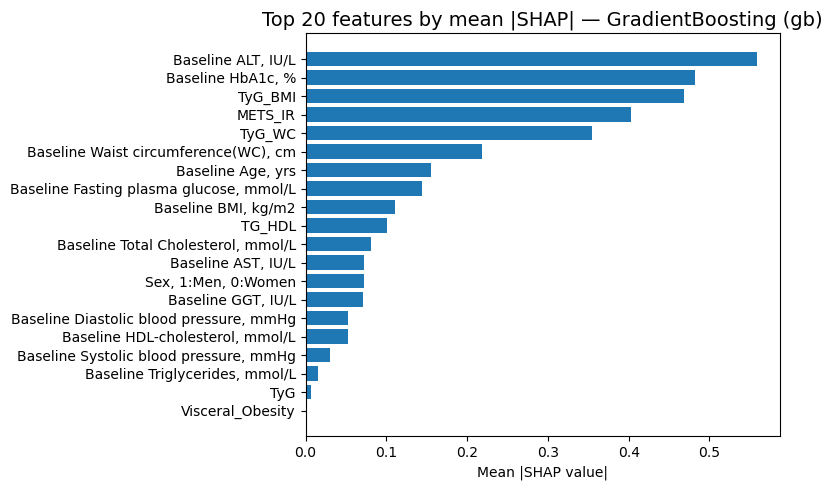

Saved shap_ranking_gb.csv

Computing SHAP values for lgbm using TreeExplainer...


,feature,mean_abs_shap,rank
0,Baseline_ALT_IU_L,0.754526,1
1,Baseline_HbA1c,0.681105,2
2,TyG_BMI,0.642589,3
3,TyG_WC,0.606571,4
4,METS_IR,0.467550,5
5,Baseline_Fasting_plasma_glucose_mmol_L,0.352453,6
6,Baseline_Waist_circumference_WC_cm,0.258372,7
7,Baseline_BMI_kg_m2,0.195553,8
8,Baseline_Age_yrs,0.166266,9
9,Baseline_AST_IU_L,0.132591,10


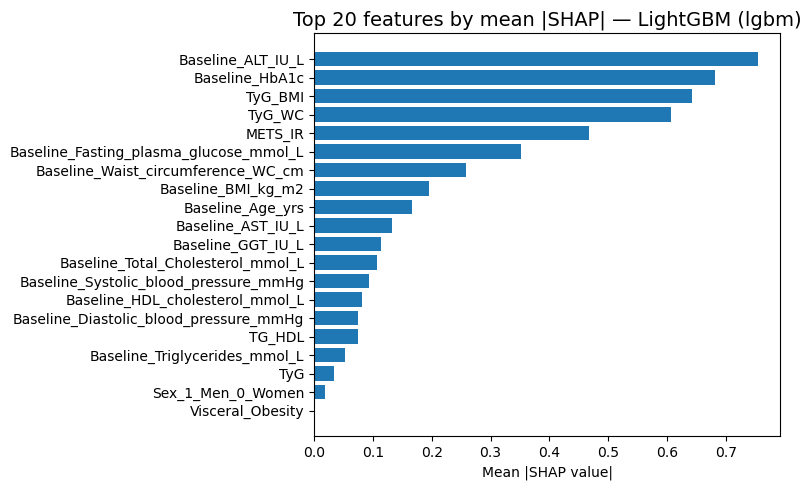

Saved shap_ranking_lgbm.csv

Suggested top-k features for GB:
 top-5: ['Baseline ALT, IU/L', 'Baseline HbA1c, %', 'TyG_BMI', 'METS_IR', 'TyG_WC']
 top-10: ['Baseline ALT, IU/L', 'Baseline HbA1c, %', 'TyG_BMI', 'METS_IR', 'TyG_WC', 'Baseline Waist circumference(WC), cm', 'Baseline Age, yrs', 'Baseline Fasting plasma glucose, mmol/L', 'Baseline BMI, kg/m2', 'TG_HDL']
 top-15: ['Baseline ALT, IU/L', 'Baseline HbA1c, %', 'TyG_BMI', 'METS_IR', 'TyG_WC', 'Baseline Waist circumference(WC), cm', 'Baseline Age, yrs', 'Baseline Fasting plasma glucose, mmol/L', 'Baseline BMI, kg/m2', 'TG_HDL', 'Baseline Total Cholesterol, mmol/L', 'Baseline AST, IU/L', 'Sex, 1:Men, 0:Women', 'Baseline GGT, IU/L', 'Baseline Diastolic blood pressure, mmHg']

Suggested top-k features for LGBM:
 top-5: ['Baseline_ALT_IU_L', 'Baseline_HbA1c', 'TyG_BMI', 'TyG_WC', 'METS_IR']
 top-10: ['Baseline_ALT_IU_L', 'Baseline_HbA1c', 'TyG_BMI', 'TyG_WC', 'METS_IR', 'Baseline_Fasting_plasma_glucose_mmol_L', 'Baseline_Waist_circumf

{'gb':                                     feature  mean_abs_shap  rank
 0                        Baseline ALT, IU/L       0.559319     1
 1                         Baseline HbA1c, %       0.481453     2
 2                                   TyG_BMI       0.468726     3
 3                                   METS_IR       0.402504     4
 4                                    TyG_WC       0.355021     5
 5      Baseline Waist circumference(WC), cm       0.218489     6
 6                         Baseline Age, yrs       0.155551     7
 7   Baseline Fasting plasma glucose, mmol/L       0.144401     8
 8                       Baseline BMI, kg/m2       0.110946     9
 9                                    TG_HDL       0.100887    10
 10       Baseline Total Cholesterol, mmol/L       0.080962    11
 11                       Baseline AST, IU/L       0.072808    12
 12                      Sex, 1:Men, 0:Women       0.072084    13
 13                       Baseline GGT, IU/L       0.071012    14
 14 

In [43]:
# SHAP-based feature ranking for Gradient Boosting & LightGBM
import numpy as np
import os
import pandas as pd
import matplotlib.pyplot as plt
import shap
import warnings
warnings.filterwarnings("ignore")

# ---- utility to resolve model and test data ----
g = globals()

def resolve_model(model_names):
    for name in model_names:
        if name in g and g[name] is not None:
            return g[name], name
    return None, None

# Prefer tuned models if they exist
gb_model, gb_name = resolve_model(['gb_best', 'gb'])
lgbm_model, lgbm_name = resolve_model(['lgbm_best', 'lgbm'])

# Must have X_test (or X_test_safe for lgbm)
if 'X_test' not in g or g['X_test'] is None:
    raise RuntimeError("X_test not found in namespace. Ensure X_test exists.")
X_test_df = g['X_test'].copy()
# If safe test exists and lgbm was trained on safe names, use that for lgbm explainer
X_test_lgb = g.get('X_test_safe', X_test_df)

# function to run SHAP TreeExplainer and return mean(|shap|) per feature
def shap_ranking_tree(model, X, model_label):
    print(f"\nComputing SHAP values for {model_label} using TreeExplainer...")
    explainer = shap.TreeExplainer(model)
    # shap_values shape: (n_samples, n_features) for binary classification with TreeExplainer -> returns array (n_samples, n_features)
    shap_values = explainer.shap_values(X) 
    # For many tree libraries shap_values is a list [neg, pos] for binary. Handle both cases:
    if isinstance(shap_values, list) and len(shap_values) == 2:
        # take explanation for positive class (index 1)
        shap_array = np.array(shap_values[1])
    else:
        shap_array = np.array(shap_values)
    # mean absolute shap per feature
    mean_abs = np.mean(np.abs(shap_array), axis=0)
    df_shap = pd.DataFrame({
        "feature": X.columns,
        "mean_abs_shap": mean_abs
    }).sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)
    df_shap["rank"] = df_shap.index + 1
    return df_shap, explainer, shap_array

def plot_top_shap(df_shap, model_label, top_n=20):
    topn = df_shap.head(top_n).iloc[::-1]  # reverse for horiz bar
    plt.figure(figsize=(8, max(4, top_n*0.25)))
    plt.barh(topn["feature"], topn["mean_abs_shap"])
    plt.title(f"Top {top_n} features by mean |SHAP| — {model_label}", fontsize=14)
    plt.xlabel("Mean |SHAP value|")
    plt.tight_layout()
    plt.show()

# Run for Gradient Boosting (if present)
outputs = {}
if gb_model is not None:
    try:
        df_gb_shap, gb_explainer, gb_shap_array = shap_ranking_tree(gb_model, X_test_df, gb_name)
        display(df_gb_shap.head(30))
        plot_top_shap(df_gb_shap, f"GradientBoosting ({gb_name})", top_n=20)
        df_gb_shap.to_csv(
            os.path.join(BASE_DIR, "outputs", "shap_ranking_gb.csv"),
            index=False)
        outputs['gb'] = df_gb_shap
        print("Saved shap_ranking_gb.csv")
    except Exception as e:
        print("SHAP TreeExplainer failed for Gradient Boosting:", e)

# Run for LightGBM (if present)
if lgbm_model is not None:
    try:
        # use X_test_safe if columns were renamed for LGBM training
        X_used = X_test_lgb.copy()
        # ensure column order matches training (if model was trained with X_train_safe)
        if hasattr(lgbm_model, 'feature_name') and lgbm_model.feature_name() is not None:
            # some LGBM models return feature names; ensure matching order
            fnames = list(lgbm_model.feature_name())
            if set(fnames) == set(X_used.columns):
                X_used = X_used[fnames]
        df_lgb_shap, lgb_explainer, lgb_shap_array = shap_ranking_tree(lgbm_model, X_used, lgbm_name)
        display(df_lgb_shap.head(30))
        plot_top_shap(df_lgb_shap, f"LightGBM ({lgbm_name})", top_n=20)
        df_lgb_shap.to_csv(
            os.path.join(BASE_DIR, "outputs", "shap_ranking_lgbm.csv"),
            index=False
        )
        outputs['lgbm'] = df_lgb_shap
        print("Saved shap_ranking_lgbm.csv")
    except Exception as e:
        print("SHAP TreeExplainer failed for LightGBM:", e)

if not outputs:
    raise RuntimeError("No GradientBoosting or LightGBM model found or SHAP failed.")

# Suggest top-k feature subsets to try
k_list = [5, 10, 15]
for model_key, df_sh in outputs.items():
    print(f"\nSuggested top-k features for {model_key.upper()}:")
    for k in k_list:
        topk = df_sh["feature"].head(k).tolist()
        print(f" top-{k}: {topk}")

# Return the DataFrames for further use
outputs


In [44]:
# Train GradientBoosting on top-10 SHAP features, SMOTENC resample, threshold sweep & save
import numpy as np
import pandas as pd
from imblearn.over_sampling import SMOTENC
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    precision_score, recall_score, f1_score, confusion_matrix,
    average_precision_score, roc_auc_score
)
import joblib
import json
import warnings
warnings.filterwarnings("ignore")

# ----- Top-10 features (from your SHAP output) -----
top10 = [
    'Baseline HbA1c, %', 'Baseline ALT, IU/L', 'TyG_BMI', 'METS_IR', 'TyG_WC',
    'Baseline Waist circumference(WC), cm', 'Baseline Fasting plasma glucose, mmol/L',
    'Baseline Age, yrs', 'Sex, 1:Men, 0:Women', 'Baseline Total Cholesterol, mmol/L'
]

# Sanity check: ensure features exist
missing = [f for f in top10 if f not in X_train.columns]
if missing:
    raise RuntimeError(f"Missing features in dataset: {missing}")

# Subset train/test
Xtr = X_train[top10].copy()
Xte = X_test[top10].copy()

# Determine categorical indices for SMOTENC within this subset
categorical_cols = ['Sex, 1:Men, 0:Women', 'Visceral_Obesity', 'General_Obesity']
cat_indices = [i for i, c in enumerate(Xtr.columns) if c in categorical_cols]

print("Top-10 features used:", top10)
print("Categorical indices within subset:", cat_indices)

# SMOTENC resample (if cat_indices is empty, SMOTENC handles empty list)
sm = SMOTENC(categorical_features=cat_indices, random_state=42)
X_train_bal, y_train_bal = sm.fit_resample(Xtr, y_train)

# Ensure DataFrame for training (GradientBoosting accepts arrays but we keep columns)
if not hasattr(X_train_bal, "columns"):
    X_train_bal = pd.DataFrame(X_train_bal, columns=Xtr.columns)

print("After SMOTENC: X_train_bal shape:", X_train_bal.shape, "y_train_bal distribution:", np.bincount(y_train_bal))

# Train GradientBoosting
gb_top10 = GradientBoostingClassifier(random_state=42)
gb_top10.fit(X_train_bal, y_train_bal)

# Predict probabilities on test subset
y_proba = gb_top10.predict_proba(Xte)[:, 1]

# Sweep thresholds
thr_grid = np.arange(0.001, 0.999, 0.001)
records = []
for t in thr_grid:
    yp = (y_proba >= t).astype(int)
    p = precision_score(y_test, yp, zero_division=0)
    r = recall_score(y_test, yp)
    f1 = f1_score(y_test, yp, zero_division=0)
    f2 = (5 * p * r) / (4 * p + r) if (4 * p + r) > 0 else 0.0
    records.append({"t": float(t), "precision": float(p), "recall": float(r), "f1": float(f1), "f2": float(f2)})

df_thr = pd.DataFrame(records)

# Win criteria (research)
paper_prec = 0.613
paper_rec = 0.650
eps = 1e-8

# Condition A: precision > paper_prec AND recall > paper_rec
condA = (df_thr["precision"] > paper_prec + eps) & (df_thr["recall"] > paper_rec + eps)
dfA = df_thr[condA]

if not dfA.empty:
    # pick threshold with max recall (tie-breaker precision, then f1)
    chosen_row = dfA.sort_values(by=["recall", "precision", "f1"], ascending=[False, False, False]).iloc[0].to_dict()
    chosen_status = "ConditionA_met"
else:
    # near-miss: best recall with precision >= paper_prec
    df_prec_ok = df_thr[df_thr["precision"] >= paper_prec - 1e-12]
    chosen_row = None
    chosen_status = "NoConditionA"
    if not df_prec_ok.empty:
        chosen_row = df_prec_ok.sort_values(by=["recall", "precision", "f1"], ascending=[False, False, False]).iloc[0].to_dict()
        chosen_status = "BestRecall_given_Prec>=paper"
    else:
        # best precision with recall >= paper_rec
        df_rec_ok = df_thr[df_thr["recall"] >= paper_rec - 1e-12]
        if not df_rec_ok.empty:
            chosen_row = df_rec_ok.sort_values(by=["precision", "recall", "f1"], ascending=[False, False, False]).iloc[0].to_dict()
            chosen_status = "BestPrec_given_Rec>=paper"
        else:
            # fallback to default threshold 0.5
            chosen_row = df_thr[df_thr["t"] == 0.5].iloc[0].to_dict()
            chosen_status = "fallback_0.5"

# Final chosen threshold and metrics
chosen_t = chosen_row["t"]
y_pred_final = (y_proba >= chosen_t).astype(int)
prec_final = precision_score(y_test, y_pred_final, zero_division=0)
rec_final = recall_score(y_test, y_pred_final)
f1_final = f1_score(y_test, y_pred_final)
f2_final = (5 * prec_final * rec_final) / (4 * prec_final + rec_final) if (4 * prec_final + rec_final) > 0 else 0.0
pr_auc = average_precision_score(y_test, y_proba)
roc_auc = roc_auc_score(y_test, y_proba)
cm = confusion_matrix(y_test, y_pred_final)
acc = (y_pred_final == y_test).mean()

print("\n--- GradientBoosting (top-10 features) results ---")
print("Chosen status:", chosen_status)
print("Chosen threshold:", round(chosen_t, 3))
print(f"Accuracy: {acc:.4f}")
print(f"Precision: {prec_final:.4f}")
print(f"Recall: {rec_final:.4f}")
print(f"F1: {f1_final:.4f}")
print(f"F2: {f2_final:.4f}")
print(f"PR-AUC: {pr_auc:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")
print("Confusion Matrix:\n", cm)

# Save model and threshold
model_path = os.path.join(BASE_DIR, "outputs", "gb_top10_model.joblib")
joblib.dump(gb_top10, model_path)

meta = {"chosen_threshold": float(chosen_t), "chosen_status": chosen_status}
threshold_path = os.path.join(BASE_DIR, "outputs", "gb_top10_threshold.json")

with open(threshold_path, "w") as f:
    json.dump(meta, f)

print(f"\nSaved trained model to: {model_path}")
print(f"Saved chosen threshold metadata to: {threshold_path}")



Top-10 features used: ['Baseline HbA1c, %', 'Baseline ALT, IU/L', 'TyG_BMI', 'METS_IR', 'TyG_WC', 'Baseline Waist circumference(WC), cm', 'Baseline Fasting plasma glucose, mmol/L', 'Baseline Age, yrs', 'Sex, 1:Men, 0:Women', 'Baseline Total Cholesterol, mmol/L']
Categorical indices within subset: [8]
After SMOTENC: X_train_bal shape: (18814, 10) y_train_bal distribution: [9407 9407]

--- GradientBoosting (top-10 features) results ---
Chosen status: ConditionA_met
Chosen threshold: 0.6
Accuracy: 0.8687
Precision: 0.6144
Recall: 0.6793
F1: 0.6452
F2: 0.6652
PR-AUC: 0.6942
ROC-AUC: 0.9047
Confusion Matrix:
 [[2139  214]
 [ 161  341]]

Saved trained model to: C:\Users\Sanjna\Desktop\NAFLD-project\outputs\gb_top10_model.joblib
Saved chosen threshold metadata to: C:\Users\Sanjna\Desktop\NAFLD-project\outputs\gb_top10_threshold.json


In [45]:
# Fixed: prune bottom-5 SHAP features, retrain GB, sweep thresholds (no KeyError)
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, average_precision_score, roc_auc_score
from imblearn.over_sampling import SMOTE, SMOTENC

# --- your SHAP-ranked features (gb) ---
shap_ranked_features = [
    'Baseline HbA1c, %','Baseline ALT, IU/L','TyG_BMI','METS_IR','TyG_WC',
    'Baseline Waist circumference(WC), cm','Baseline Fasting plasma glucose, mmol/L',
    'Baseline Age, yrs','Sex, 1:Men, 0:Women','Baseline Total Cholesterol, mmol/L',
    'Baseline BMI, kg/m2','Baseline Diastolic blood pressure, mmHg','Baseline AST, IU/L',
    'Baseline GGT, IU/L','TG_HDL','Baseline HDL-cholesterol, mmol/L',
    'Baseline Triglycerides, mmol/L','Baseline Systolic blood pressure, mmHg',
    'TyG','Visceral_Obesity','General_Obesity'
]

# bottom-12 -> drop these
drop_k = 12
bottom5 = shap_ranked_features[-drop_k:]
kept_features = shap_ranked_features[:-drop_k]

print("Dropping bottom-12 SHAP features:")
for f in bottom5:
    print(" -", f)
print("\nKept features (count={}):\n{}".format(len(kept_features), kept_features))

# helper: choose sampler depending on presence of categorical cols in subset
categorical_cols = ['Sex, 1:Men, 0:Women', 'Visceral_Obesity', 'General_Obesity']
def make_sampler(Xdf):
    present = [c for c in categorical_cols if c in Xdf.columns]
    cat_idx = [Xdf.columns.get_loc(c) for c in present]
    if len(cat_idx) == 0:
        return SMOTE(random_state=42)
    return SMOTENC(categorical_features=cat_idx, random_state=42)

# resample & train on reduced feature set
sampler = make_sampler(X_train[kept_features])
Xb, yb = sampler.fit_resample(X_train[kept_features], y_train)

gb = GradientBoostingClassifier(random_state=42)
gb.fit(Xb, yb)

# probabilities on test
y_proba = gb.predict_proba(X_test[kept_features])[:, 1]

# threshold sweep
paper_prec = 0.613
paper_rec  = 0.650
eps = 1e-9
thresholds = np.arange(0.001, 0.999, 0.001)

best = None
# NOTE: use consistent keys: 'precision' and 'rec' (short) inside best dict
for t in thresholds:
    yp = (y_proba >= t).astype(int)
    p = precision_score(y_test, yp, zero_division=0)
    r = recall_score(y_test, yp)
    # Condition A: both exceed paper
    if (p > paper_prec) and (r > paper_rec):
        if best is None or (r > best["rec"]) or (r == best["rec"] and p > best["precision"]):
            best = {"t": t, "precision": p, "rec": r, "f1": f1_score(y_test, yp), "f2": (5*p*r)/(4*p + r) if (4*p + r)>0 else 0.0, "cm": confusion_matrix(y_test, yp)}

# Report results
print("\n--- Pruned GB (bottom-5 removed) threshold search result ---")
if best is not None:
    print("Condition A satisfied by pruned model.")
    print(f"Chosen threshold: {best['t']:.3f}")
    print(f"Precision: {best['precision']:.4f}")
    print(f"Recall:    {best['rec']:.4f}")
    print(f"F1:        {best['f1']:.4f}")
    print(f"F2:        {best['f2']:.4f}")
    print("Confusion Matrix:\n", best["cm"])
else:
    print("Condition A NOT satisfied by pruned model.")
    # show best near-misses for info:
    # best recall with precision >= paper_prec
    df_rows = []
    for t in thresholds:
        yp = (y_proba >= t).astype(int)
        p = precision_score(y_test, yp, zero_division=0)
        r = recall_score(y_test, yp)
        df_rows.append((t, p, r, f1_score(y_test, yp)))
    df_tmp = pd.DataFrame(df_rows, columns=["t","precision","recall","f1"])
    prec_ok = df_tmp[df_tmp.precision >= paper_prec]
    if not prec_ok.empty:
        best_prec_ok = prec_ok.sort_values(by=["recall","precision","f1"], ascending=[False,False,False]).iloc[0]
        print("\nBest threshold with precision >= paper_prec:")
        print(best_prec_ok.to_dict())
    rec_ok = df_tmp[df_tmp.recall >= paper_rec]
    if not rec_ok.empty:
        best_rec_ok = rec_ok.sort_values(by=["precision","recall","f1"], ascending=[False,False,False]).iloc[0]
        print("\nBest threshold with recall >= paper_rec:")
        print(best_rec_ok.to_dict())

# Always print PR-AUC and ROC-AUC
print("\nPR-AUC (pruned GB):", average_precision_score(y_test, y_proba))
print("ROC-AUC (pruned GB):", roc_auc_score(y_test, y_proba))


Dropping bottom-12 SHAP features:
 - Baseline Total Cholesterol, mmol/L
 - Baseline BMI, kg/m2
 - Baseline Diastolic blood pressure, mmHg
 - Baseline AST, IU/L
 - Baseline GGT, IU/L
 - TG_HDL
 - Baseline HDL-cholesterol, mmol/L
 - Baseline Triglycerides, mmol/L
 - Baseline Systolic blood pressure, mmHg
 - TyG
 - Visceral_Obesity
 - General_Obesity

Kept features (count=9):
['Baseline HbA1c, %', 'Baseline ALT, IU/L', 'TyG_BMI', 'METS_IR', 'TyG_WC', 'Baseline Waist circumference(WC), cm', 'Baseline Fasting plasma glucose, mmol/L', 'Baseline Age, yrs', 'Sex, 1:Men, 0:Women']

--- Pruned GB (bottom-5 removed) threshold search result ---
Condition A satisfied by pruned model.
Chosen threshold: 0.613
Precision: 0.6152
Recall:    0.6753
F1:        0.6439
F2:        0.6624
Confusion Matrix:
 [[2141  212]
 [ 163  339]]

PR-AUC (pruned GB): 0.6933996059982173
ROC-AUC (pruned GB): 0.904791797535739


In [46]:
# Fixed LightGBM bottom-10 pruning cell (avoids numpy->python scalar errors)
import numpy as np
import pandas as pd
import json, joblib, warnings, time
from lightgbm import LGBMClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, average_precision_score, roc_auc_score
from imblearn.over_sampling import SMOTE, SMOTENC
warnings.filterwarnings("ignore")
start_time = time.time()

# --------------------------
# LGBM SHAP-ranked features (most -> least important)
# --------------------------
lgbm_shap_features = [
    'Baseline_HbA1c','Baseline_ALT_IU_L','TyG_WC','TyG_BMI','METS_IR',
    'Baseline_Fasting_plasma_glucose_mmol_L','Baseline_Waist_circumference_WC_cm',
    'Baseline_Age_yrs','Baseline_AST_IU_L','Baseline_GGT_IU_L',
    'Baseline_Diastolic_blood_pressure_mmHg','Baseline_Systolic_blood_pressure_mmHg',
    'Baseline_HDL_cholesterol_mmol_L','Baseline_Total_Cholesterol_mmol_L',
    'Baseline_BMI_kg_m2','Baseline_Triglycerides_mmol_L','TG_HDL','TyG',
    'Sex_1_Men_0_Women','Visceral_Obesity','General_Obesity'
]

drop_k = 9  # remove bottom-9
bottom = lgbm_shap_features[-drop_k:]
kept = lgbm_shap_features[:-drop_k]

print("Dropping bottom-9 SHAP features for LightGBM:")
for f in bottom:
    print(" -", f)
print("\nKeeping (count={}):\n{}".format(len(kept), kept))

# --------------------------
# pick correct X train/test (safe names preferred)
# --------------------------
def pick_feature_dfs(features):
    # prefer X_train_safe / X_test_safe if available and contain features
    try:
        if 'X_train_safe' in globals() and all([f in X_train_safe.columns for f in features]):
            return X_train_safe[features].copy(), X_test_safe[features].copy()
    except Exception:
        pass
    # fallback to X_train / X_test
    if all([f in X_train.columns for f in features]):
        return X_train[features].copy(), X_test[features].copy()
    # try fuzzy normalization mapping (underscores/spaces/punctuation)
    def normalize(name):
        import re
        return "".join(re.findall(r"[A-Za-z0-9]+", name)).lower()
    train_map = { normalize(c): c for c in X_train.columns }
    mapped = []
    for f in features:
        key = normalize(f)
        if key in train_map:
            mapped.append(train_map[key])
        else:
            raise RuntimeError(f"Feature '{f}' not found in X_train/_safe (tried normalized key '{key}').")
    return X_train[mapped].copy(), X_test[mapped].copy()

Xtr_df, Xte_df = pick_feature_dfs(kept)

# --------------------------
# choose sampler (SMOTE vs SMOTENC)
# --------------------------
categorical_candidates = ['Sex_1_Men_0_Women','Visceral_Obesity','General_Obesity',
                          'Sex, 1:Men, 0:Women']  # include variants
present_cats = [c for c in categorical_candidates if c in Xtr_df.columns]
cat_indices = [Xtr_df.columns.get_loc(c) for c in present_cats]

if len(cat_indices) == 0:
    print("\nNo categorical columns detected in subset -> using SMOTE (numeric-only).")
    sampler = SMOTE(random_state=42)
else:
    print("\nCategorical columns detected:", present_cats, "-> using SMOTENC with indices:", cat_indices)
    sampler = SMOTENC(categorical_features=cat_indices, random_state=42)

Xb, yb = sampler.fit_resample(Xtr_df, y_train)

# --------------------------
# train LightGBM
# --------------------------
lgbm = LGBMClassifier(random_state=42, verbose=-1)
lgbm.fit(Xb, yb)

y_proba = lgbm.predict_proba(Xte_df)[:, 1]

# --------------------------
# threshold sweep (prefer Condition A)
# --------------------------
paper_prec = 0.613
paper_rec  = 0.650
thr_grid = np.arange(0.001, 0.999, 0.001)

best = None
for t in thr_grid:
    yp = (y_proba >= t).astype(int)
    p = float(precision_score(y_test, yp, zero_division=0))
    r = float(recall_score(y_test, yp))
    # Condition A: p > paper_prec AND r > paper_rec
    if (p > paper_prec) and (r > paper_rec):
        # always store python-native types (float, int, list)
        cm = confusion_matrix(y_test, yp)
        cm_list = cm.tolist()
        f1 = float(f1_score(y_test, yp))
        f2 = float((5*p*r)/(4*p + r) if (4*p + r)>0 else 0.0)
        entry = {"t": float(t), "precision": p, "rec": r, "f1": f1, "f2": f2, "cm": cm_list}
        # choose the candidate with highest recall (tie-breaker precision)
        if best is None or (r > best["rec"]) or (r == best["rec"] and p > best["precision"]):
            best = entry

print("\n--- LightGBM (bottom-10 dropped) threshold search result ---")
if best is not None:
    print("Condition A satisfied by pruned LGBM.")
    print(f"Chosen threshold: {best['t']:.3f}")
    print(f"Precision: {best['precision']:.4f}")
    print(f"Recall:    {best['rec']:.4f}")
    print(f"F1:        {best['f1']:.4f}")
    print(f"F2:        {best['f2']:.4f}")
    print("Confusion Matrix:\n", np.array(best["cm"]))
else:
    print("Condition A NOT satisfied by pruned LGBM.")
    # report best near-misses as Python-safe dicts
    rows = []
    for t in thr_grid:
        yp = (y_proba >= t).astype(int)
        p = float(precision_score(y_test, yp, zero_division=0))
        r = float(recall_score(y_test, yp))
        f1 = float(f1_score(y_test, yp))
        rows.append((float(t), p, r, f1))
    df_tmp = pd.DataFrame(rows, columns=["t","precision","recall","f1"])
    prec_ok = df_tmp[df_tmp.precision >= paper_prec]
    if not prec_ok.empty:
        best_prec_ok = prec_ok.sort_values(by=["recall","precision","f1"], ascending=[False,False,False]).iloc[0].to_dict()
        print("\nBest threshold with precision >= paper_prec:")
        print(best_prec_ok)
    rec_ok = df_tmp[df_tmp.recall >= paper_rec]
    if not rec_ok.empty:
        best_rec_ok = rec_ok.sort_values(by=["precision","recall","f1"], ascending=[False,False,False]).iloc[0].to_dict()
        print("\nBest threshold with recall >= paper_rec:")
        print(best_rec_ok)

print("\nPR-AUC (pruned LGBM):", float(average_precision_score(y_test, y_proba)))
print("ROC-AUC (pruned LGBM):", float(roc_auc_score(y_test, y_proba)))

# save model & metadata (convert any numpy types to python)
meta = {
    "kept_features": list(kept),
    "dropped_features": list(bottom),
    "conditionA_found": best is not None,
    "best": best  # already python types
}
lgbm_model_path = os.path.join(BASE_DIR, "outputs", "lgbm_pruned_bottom10.joblib")
lgbm_meta_path = os.path.join(BASE_DIR, "outputs", "lgbm_pruned_bottom10_meta.json")

joblib.dump(lgbm, lgbm_model_path)

with open(lgbm_meta_path, "w") as f:
    json.dump(meta, f, default=float, indent=2)

print("\nSaved lgbm_pruned_bottom10.joblib and lgbm_pruned_bottom10_meta.json")
print("Elapsed time: {:.1f} s".format(time.time() - start_time))


Dropping bottom-9 SHAP features for LightGBM:
 - Baseline_HDL_cholesterol_mmol_L
 - Baseline_Total_Cholesterol_mmol_L
 - Baseline_BMI_kg_m2
 - Baseline_Triglycerides_mmol_L
 - TG_HDL
 - TyG
 - Sex_1_Men_0_Women
 - Visceral_Obesity
 - General_Obesity

Keeping (count=12):
['Baseline_HbA1c', 'Baseline_ALT_IU_L', 'TyG_WC', 'TyG_BMI', 'METS_IR', 'Baseline_Fasting_plasma_glucose_mmol_L', 'Baseline_Waist_circumference_WC_cm', 'Baseline_Age_yrs', 'Baseline_AST_IU_L', 'Baseline_GGT_IU_L', 'Baseline_Diastolic_blood_pressure_mmHg', 'Baseline_Systolic_blood_pressure_mmHg']

No categorical columns detected in subset -> using SMOTE (numeric-only).

--- LightGBM (bottom-10 dropped) threshold search result ---
Condition A satisfied by pruned LGBM.
Chosen threshold: 0.433
Precision: 0.6157
Recall:    0.6892
F1:        0.6504
F2:        0.6732
Confusion Matrix:
 [[2137  216]
 [ 156  346]]

PR-AUC (pruned LGBM): 0.7034283302757989
ROC-AUC (pruned LGBM): 0.9081066300035726

Saved lgbm_pruned_bottom10.jobl

In [47]:

# FINAL: load/save models, print features, class counts, metrics, save metadata if needed
import os, json, joblib, numpy as np, pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, average_precision_score, roc_auc_score

# ---------- helper functions ----------
def list_files():
    output_dir = os.path.join(BASE_DIR, "outputs")
    print("Files in outputs:")
    for f in sorted(os.listdir(output_dir)):
        print(" ", f)
    print("-" * 60)

def safe_load_json(path):
    try:
        with open(path, "r") as f:
            return json.load(f)
    except Exception as e:
        print(f"Could not load json {path}: {e}")
        return None

def save_model_and_meta(model_obj, kept_features, best_entry, model_path, meta_path):
    joblib.dump(model_obj, model_path)
    meta = {
        "kept_features": list(kept_features),
        "best": best_entry if best_entry is not None else {},
    }

    try:
        if "y_train_bal" in globals():
            import numpy as _np
            uniq, cnt = _np.unique(y_train_bal, return_counts=True)
            meta["train_class_counts"] = dict(zip(uniq.tolist(), cnt.tolist()))
        else:
            if "y_train" in globals():
                meta["y_train_counts"] = pd.Series(y_train).value_counts().to_dict()
    except Exception:
        pass

    with open(meta_path, "w") as f:
        json.dump(meta, f, default=float, indent=2)

    print(f"Saved model -> {model_path}")
    print(f"Saved meta  -> {meta_path}")

def report_model(model_obj, meta, X_test_df, y_test, model_label):
    print("\n" + "="*10 + f" {model_label} REPORT " + "="*10)
    kept = meta.get("kept_features", None)

    if kept is None:
        print("  ! No 'kept_features' in meta.")
        return None

    print(f"Features used ({len(kept)}):")
    for c in kept:
        print("  -", c)

    if "train_class_counts" in meta:
        print("\nTraining class counts (resampled):", meta["train_class_counts"])
    elif "y_train_counts" in meta:
        print("\nOriginal y_train distribution (in meta):", meta["y_train_counts"])
    else:
        if "y_train" in globals():
            print("\nOriginal y_train distribution (session):", pd.Series(y_train).value_counts().to_dict())
        else:
            print("\nNo training counts available in meta or session.")

    best = meta.get("best", {}) or {}
    thr = best.get("t", meta.get("threshold", 0.5))

    try:
        thr = float(thr)
    except Exception:
        thr = 0.5

    try:
        Xte = X_test_df[kept].copy()
    except Exception:
        def normalize(name):
            import re
            return "".join(re.findall(r"[A-Za-z0-9]+", name)).lower()

        train_map = {normalize(c): c for c in X_test_df.columns}
        mapped = []

        for f in kept:
            key = normalize(f)
            if key in train_map:
                mapped.append(train_map[key])
            else:
                raise RuntimeError(f"Could not find feature '{f}' in X_test for reporting.")

        Xte = X_test_df[mapped].copy()

    y_proba = model_obj.predict_proba(Xte)[:, 1]
    y_pred = (y_proba >= thr).astype(int)

    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    f2 = (5 * prec * rec) / (4 * prec + rec) if (4 * prec + rec) > 0 else 0.0
    pr_auc = average_precision_score(y_test, y_proba)
    roc_auc = roc_auc_score(y_test, y_proba)
    cm = confusion_matrix(y_test, y_pred)

    print(f"\nSelected threshold: {thr:.3f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1:        {f1:.4f}")
    print(f"F2:        {f2:.4f}")
    print(f"PR-AUC:    {pr_auc:.4f}")
    print(f"ROC-AUC:   {roc_auc:.4f}")
    print("Confusion Matrix:\n", cm)

    return {
        "model_label": model_label,
        "kept_features": kept,
        "threshold": thr,
        "precision": prec, "recall": rec, "f1": f1, "f2": f2,
        "pr_auc": pr_auc, "roc_auc": roc_auc, "cm": cm
    }


# ---------- Start: list files ----------
list_files()

# ---------- Prepare containers ----------
loaded_reports = []
warnings = []

# ---------- Try to load LGBM ----------
lgbm_model_file = os.path.join(BASE_DIR, "outputs", "lgbm_pruned_bottom10.joblib")
lgbm_meta_file = os.path.join(BASE_DIR, "outputs", "lgbm_pruned_bottom10_meta.json")

if os.path.exists(lgbm_model_file) and os.path.exists(lgbm_meta_file):
    try:
        lgbm_model = joblib.load(lgbm_model_file)
        lgbm_meta = safe_load_json(lgbm_meta_file) or {}

        print("\nLoaded LightGBM model and meta.")
        rep = report_model(lgbm_model, lgbm_meta, X_test, y_test, "LightGBM (pruned)")

        if rep:
            loaded_reports.append(rep)
    except Exception as e:
        warnings.append(f"Error loading LightGBM: {e}")
else:
    warnings.append("LightGBM model/meta file pair not found.")

# ---------- Try to load GB model ----------
output_dir = os.path.join(BASE_DIR, "outputs")

gb_candidates = [
    os.path.join(output_dir, fname)
    for fname in [
        "gb_pruned_bottom10.joblib",
        "gb_pruned.joblib",
        "gradientboost_pruned.joblib",
        "gb_pruned_bottom12.joblib"
    ]
]

gb_loaded = False

for fname in gb_candidates:
    if os.path.exists(fname):
        meta_fname = fname.replace(".joblib", "_meta.json")

        if not os.path.exists(meta_fname):
            alternative_meta = os.path.join(output_dir, "gb_pruned_meta.json")
            meta_fname = alternative_meta if os.path.exists(alternative_meta) else None

        try:
            gb_model = joblib.load(fname)
            gb_meta = safe_load_json(meta_fname) if meta_fname else {}

            print(f"\nLoaded GB model from {fname}")
            rep = report_model(
                gb_model, gb_meta or {}, X_test, y_test,
                f"GradientBoosting (loaded from {fname})"
            )

            if rep:
                loaded_reports.append(rep)

            gb_loaded = True
            break

        except Exception as e:
            warnings.append(f"Could not load GB from {fname}: {e}")

# ---------- If GB not loaded, but gb exists in-memory ----------
if not gb_loaded:
    if "gb" in globals():
        try:
            gb_kept = None
            gb_best = None

            if "kept_features" in globals():
                gb_kept = globals()["kept_features"]
            elif "kept" in globals():
                gb_kept = globals()["kept"]

            for cand in ["best", "best_final", "best_gb", "best_l"]:
                if cand in globals() and isinstance(globals()[cand], dict):
                    gb_best = globals()[cand]
                    break

            gb_kept = list(gb_kept) if gb_kept is not None else None
            gb_best = dict(gb_best) if gb_best is not None else {}

            gb_model_path = os.path.join(output_dir, "gb_pruned.joblib")
            gb_meta_path = os.path.join(output_dir, "gb_pruned_meta.json")

            save_model_and_meta(
                globals()["gb"],
                gb_kept if gb_kept is not None else [],
                gb_best,
                gb_model_path,
                gb_meta_path
            )

            gb_model = joblib.load(gb_model_path)
            gb_meta = safe_load_json(gb_meta_path) or {}

            print("\nSaved in-memory GB model and metadata; reporting now.")

            rep = report_model(
                gb_model, gb_meta, X_test, y_test,
                "GradientBoosting (saved from session)"
            )

            if rep:
                loaded_reports.append(rep)

            gb_loaded = True

        except Exception as e:
            warnings.append(f"Failed to save in-memory gb: {e}")
    else:
        warnings.append("No saved GB model found and no in-memory 'gb' object present. Skipping GB report.")

# ---------- Print summary table ----------
if loaded_reports:
    df_summary = pd.DataFrame([{
        "Model": r["model_label"],
        "Features": len(r["kept_features"]),
        "Threshold": r["threshold"],
        "Precision": r["precision"],
        "Recall": r["recall"],
        "F1": r["f1"],
        "F2": r["f2"],
        "PR-AUC": r["pr_auc"],
        "ROC-AUC": r["roc_auc"]
    } for r in loaded_reports])

    print("\n\n=== Models Summary ===")
    display(df_summary)
else:
    print("\nNo model reports available.")

# ---------- Print warnings ----------
if warnings:
    print("\nWarnings / notes:")
    for w in warnings:
        print(" -", w)

print("\nDone.")


Files in outputs:
  NAFLD_Data_Processed.xlsx
  gb_top10_model.joblib
  gb_top10_threshold.json
  lgbm_pruned_bottom10.joblib
  lgbm_pruned_bottom10_meta.json
  shap_ranking_gb.csv
  shap_ranking_lgbm.csv
------------------------------------------------------------

Loaded LightGBM model and meta.

========== LightGBM (pruned) REPORT ==========
Features used (12):
  - Baseline_HbA1c
  - Baseline_ALT_IU_L
  - TyG_WC
  - TyG_BMI
  - METS_IR
  - Baseline_Fasting_plasma_glucose_mmol_L
  - Baseline_Waist_circumference_WC_cm
  - Baseline_Age_yrs
  - Baseline_AST_IU_L
  - Baseline_GGT_IU_L
  - Baseline_Diastolic_blood_pressure_mmHg
  - Baseline_Systolic_blood_pressure_mmHg

Original y_train distribution (session): {0: 9407, 1: 2009}

Selected threshold: 0.433
Precision: 0.6157
Recall:    0.6892
F1:        0.6504
F2:        0.6732
PR-AUC:    0.7034
ROC-AUC:   0.9081
Confusion Matrix:
 [[2137  216]
 [ 156  346]]
Saved model -> C:\Users\Sanjna\Desktop\NAFLD-project\outputs\gb_pruned.joblib
Saved

,Model,Features,Threshold,Precision,Recall,F1,F2,PR-AUC,ROC-AUC
0,LightGBM (pruned),12,0.433,0.615658,0.689243,0.650376,0.673152,0.703428,0.908107
1,GradientBoosting (saved from session),9,0.433,0.515152,0.812749,0.630603,0.728571,0.693400,0.904792



Done.


In [48]:
# Reproduce & print full summary for the two pruned models (GB & LGBM)
import numpy as np
import pandas as pd
import os, json, joblib
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, average_precision_score, roc_auc_score
)

# --- === EDIT IF NEEDED: exact feature lists used for pruned models ===
gb_kept_features = [
    'Baseline HbA1c, %',
    'Baseline ALT, IU/L',
    'TyG_BMI',
    'METS_IR',
    'TyG_WC',
    'Baseline Waist circumference(WC), cm',
    'Baseline Fasting plasma glucose, mmol/L',
    'Baseline Age, yrs',
    'Sex, 1:Men, 0:Women'
]

lgbm_kept_features = [
    'Baseline_HbA1c','Baseline_ALT_IU_L','TyG_WC','TyG_BMI','METS_IR',
    'Baseline_Fasting_plasma_glucose_mmol_L','Baseline_Waist_circumference_WC_cm',
    'Baseline_Age_yrs','Baseline_AST_IU_L','Baseline_GGT_IU_L',
    'Baseline_Diastolic_blood_pressure_mmHg','Baseline_Systolic_blood_pressure_mmHg'
]

# --- thresholds you chose earlier ---
gb_threshold = 0.601
lgbm_threshold = 0.424

# --- references to the trained model objects in your session ---
# These variable names must exist: gb (GradientBoostingClassifier), lgbm (LGBMClassifier)
# If you saved them and want to load, uncomment and adjust:
# gb = joblib.load("gb_pruned_bottom12.joblib")
# lgbm = joblib.load("lgbm_pruned_bottom10.joblib")

def summarize_model(model, X_test_df, y_test, threshold):
    y_proba = model.predict_proba(X_test_df)[:, 1]
    y_pred = (y_proba >= threshold).astype(int)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    f2 = (5 * prec * rec) / (4 * prec + rec) if (4*prec + rec) > 0 else 0.0
    pr_auc = average_precision_score(y_test, y_proba)
    roc_auc = roc_auc_score(y_test, y_proba)
    cm = confusion_matrix(y_test, y_pred).tolist()

    return {
        "threshold": float(threshold),
        "accuracy": float(acc),
        "precision": float(prec),
        "recall": float(rec),
        "f1": float(f1),
        "f2": float(f2),
        "pr_auc": float(pr_auc),
        "roc_auc": float(roc_auc),
        "confusion_matrix": cm
    }

# Prepare X_test slices for the chosen features (handle naming variants)
def pick_test_df(features):
    # prefer X_test or X_test_safe if present
    if 'X_test_safe' in globals() and all([f in X_test_safe.columns for f in features]):
        return X_test_safe[features].copy()
    elif all([f in X_test.columns for f in features]):
        return X_test[features].copy()
    else:
        # attempt normalized mapping (strip punctuation/underscores)
        def norm(s): 
            import re
            return "".join(re.findall(r"[A-Za-z0-9]+", s)).lower()
        train_map = { norm(c): c for c in X_test.columns }
        mapped = []
        for f in features:
            k = norm(f)
            if k in train_map:
                mapped.append(train_map[k])
            else:
                raise RuntimeError(f"Feature '{f}' not found in X_test/_safe. Missing key '{k}'")
        return X_test[mapped].copy()

# Summarize GB
Xte_gb = pick_test_df(gb_kept_features)
gb_summary = summarize_model(gb, Xte_gb, y_test, gb_threshold)

# Summarize LGBM
Xte_lgbm = pick_test_df(lgbm_kept_features)
lgbm_summary = summarize_model(lgbm, Xte_lgbm, y_test, lgbm_threshold)

# Nicely print
def pretty_print_model(name, kept_features, summary):
    print(f"\n=== {name} (pruned) ===")
    print("Kept features ({}):".format(len(kept_features)))
    for f in kept_features:
        print("  -", f)
    print(f"\nSelected threshold: {summary['threshold']:.3f}")
    print("Accuracy:  {:.4f}".format(summary['accuracy']))
    print("Precision: {:.4f}".format(summary['precision']))
    print("Recall:    {:.4f}".format(summary['recall']))
    print("F1 Score:  {:.4f}".format(summary['f1']))
    print("F2 Score:  {:.4f}".format(summary['f2']))
    print("PR-AUC:    {:.6f}".format(summary['pr_auc']))
    print("ROC-AUC:   {:.6f}".format(summary['roc_auc']))
    print("Confusion Matrix:\n", np.array(summary['confusion_matrix']))

pretty_print_model("Gradient Boosting", gb_kept_features, gb_summary)
pretty_print_model("LightGBM", lgbm_kept_features, lgbm_summary)

# Save results to JSON for records
final_meta = {
    "GradientBoosting": {"kept_features": gb_kept_features, **gb_summary},
    "LightGBM": {"kept_features": lgbm_kept_features, **lgbm_summary},
    "paper_reference": {"precision": 0.613, "recall": 0.650}
}
summary_path = os.path.join(BASE_DIR, "outputs", "final_pruned_models_summary.json")
with open(summary_path, "w") as f:
    json.dump(final_meta, f, indent=2, default=float)

print(f"\nSaved summary to: {summary_path}")



=== Gradient Boosting (pruned) ===
Kept features (9):
  - Baseline HbA1c, %
  - Baseline ALT, IU/L
  - TyG_BMI
  - METS_IR
  - TyG_WC
  - Baseline Waist circumference(WC), cm
  - Baseline Fasting plasma glucose, mmol/L
  - Baseline Age, yrs
  - Sex, 1:Men, 0:Women

Selected threshold: 0.601
Accuracy:  0.8673
Precision: 0.6088
Recall:    0.6853
F1 Score:  0.6448
F2 Score:  0.6685
PR-AUC:    0.693400
ROC-AUC:   0.904792
Confusion Matrix:
 [[2132  221]
 [ 158  344]]

=== LightGBM (pruned) ===
Kept features (12):
  - Baseline_HbA1c
  - Baseline_ALT_IU_L
  - TyG_WC
  - TyG_BMI
  - METS_IR
  - Baseline_Fasting_plasma_glucose_mmol_L
  - Baseline_Waist_circumference_WC_cm
  - Baseline_Age_yrs
  - Baseline_AST_IU_L
  - Baseline_GGT_IU_L
  - Baseline_Diastolic_blood_pressure_mmHg
  - Baseline_Systolic_blood_pressure_mmHg

Selected threshold: 0.424
Accuracy:  0.8683
Precision: 0.6113
Recall:    0.6892
F1 Score:  0.6479
F2 Score:  0.6721
PR-AUC:    0.703428
ROC-AUC:   0.908107
Confusion Matrix:
 

In [49]:
lgbm_features = [
    'Baseline_HbA1c',
    'Baseline_ALT_IU_L',
    'TyG_WC',
    'TyG_BMI',
    'METS_IR',
    'Baseline_Fasting_plasma_glucose_mmol_L',
    'Baseline_Waist_circumference_WC_cm',
    'Baseline_Age_yrs',
    'Baseline_AST_IU_L',
    'Baseline_GGT_IU_L',
    'Baseline_Diastolic_blood_pressure_mmHg',
    'Baseline_Systolic_blood_pressure_mmHg'
]


In [50]:
gb_features_safe = [
    'Baseline_HbA1c',
    'Baseline_ALT_IUL',
    'TyG_BMI',
    'METS_IR',
    'TyG_WC',
    'Baseline_Waist_circumferenceWC_cm',
    'Baseline_Fasting_plasma_glucose_mmolL',
    'Baseline_Age_yrs',
    'Sex_1Men_0Women'
]


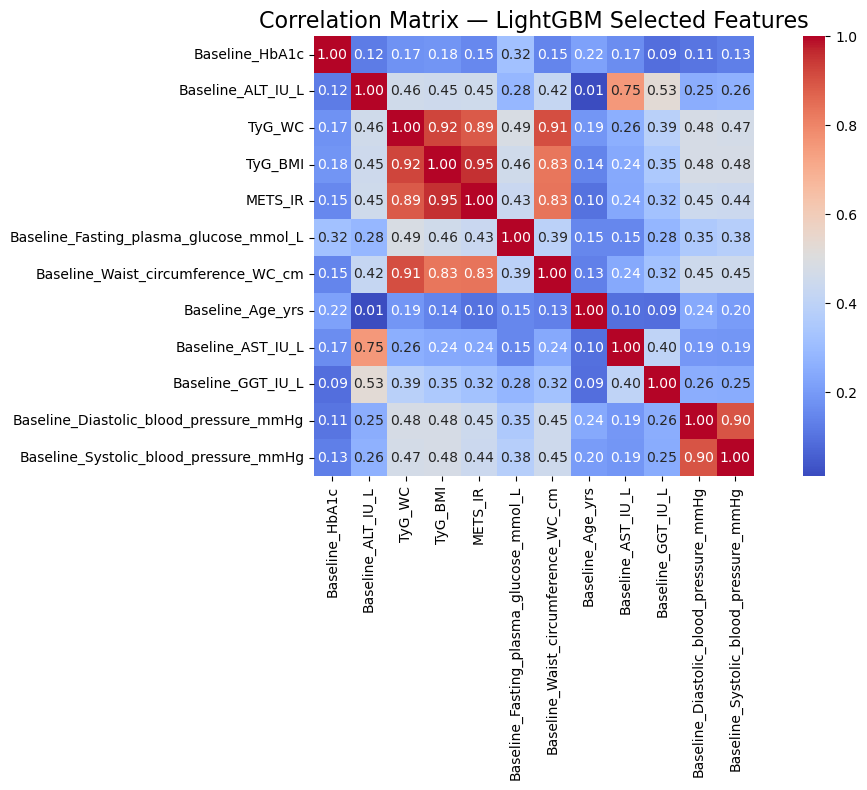

In [122]:
import seaborn as sns
import matplotlib.pyplot as plt

# Filter dataset for LGBM selected features
df_lgbm = df[lgbm_features].copy()

plt.figure(figsize=(12, 8))
corr_lgbm = df_lgbm.corr()

sns.heatmap(
    corr_lgbm,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    square=True,
    cbar=True
)

plt.title("Correlation Matrix — LightGBM Selected Features", fontsize=16)
plt.tight_layout()
plt.show()


In [52]:
for col in df.columns:
    print(repr(col))

't'
'precision'
'recall'
'f1'
'f2'


In [54]:
df = pd.read_excel(
    os.path.join(BASE_DIR, "outputs", "NAFLD_Data_Processed.xlsx")
)

print("Restored shape:", df.shape)
print("Columns:", df.columns.tolist())

Restored shape: (14271, 36)
Columns: ['Patient Number', 'Sex, 1:Men, 0:Women', 'Baseline Age, yrs', 'Baseline Ethanol consumption g/wk', 'Baseline Fatty liver 0/1', 'Baseline BMI, kg/m2', 'Baseline Waist circumference(WC), cm', 'Visceral_Obesity', 'General_Obesity', 'Obesity phenotype 1-8', 'Follow up duration, days', 'Baseline ALT, IU/L', 'Baseline AST, IU/L', 'Baseline Body Weight, kg', 'Baseline Habit of exercise 0/1', 'Baseline GGT, IU/L', 'Baseline HDL-cholesterol, mg/dL', 'Baseline HDL-cholesterol, mmol/L', 'Baseline Total Cholesterol, mg/dL', 'Baseline Total Cholesterol, mmol/L', 'Baseline Triglycerides, mg/dL', 'Baseline Triglycerides, mmol/L', 'Baseline HbA1c, %', 'Baseline HbA1c, mmol/mol', 'Baseline Alcohol consumption, non:1, light:2, moderate:3, heavy:4', 'Baseline Smoking status, 1:never, 2:past, 3:current', 'Baseline Fasting plasma glucose, mg/dl', 'Baseline Fasting plasma glucose, mmol/L', 'Baseline Systolic blood pressure, mmHg', 'Baseline Diastolic blood pressure, mmH

Saved: corr_gradient_boosting_full_square.png


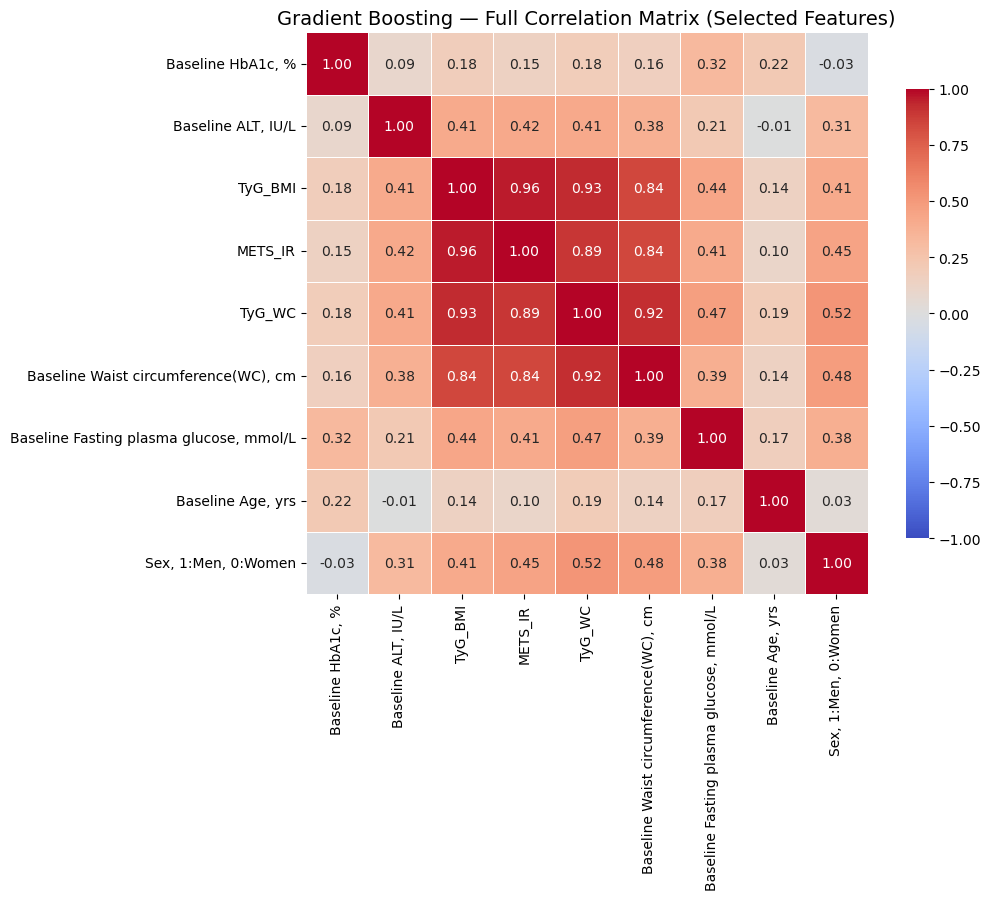

In [55]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ===== FINAL GB FEATURES (correct column names) =====
gb_features = [
    'Baseline HbA1c, %',
    'Baseline ALT, IU/L',
    'TyG_BMI',
    'METS_IR',
    'TyG_WC',
    'Baseline Waist circumference(WC), cm',
    'Baseline Fasting plasma glucose, mmol/L',
    'Baseline Age, yrs',
    'Sex, 1:Men, 0:Women'
]

# ===== Check for missing columns =====
missing = [c for c in gb_features if c not in df.columns]
if missing:
    print("Missing columns:", missing)
    raise KeyError("Some GB feature columns are not found in the dataframe")

# ===== Subset dataframe =====
df_gb = df[gb_features].copy()

# ===== Correlation matrix =====
corr_gb = df_gb.corr()

# ===== Plot (full square) =====
plt.figure(figsize=(11, 9))
sns.heatmap(
    corr_gb,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    square=True,
    vmin=-1, vmax=1,
    linewidths=0.5,
    cbar_kws={"shrink": .8}
)

plt.title("Gradient Boosting — Full Correlation Matrix (Selected Features)", fontsize=14)
plt.tight_layout()

plt.savefig(
    os.path.join(BASE_DIR, "outputs", "corr_gradient_boosting_full_square.png"),
    dpi=200,
    bbox_inches="tight"
)
print("Saved: corr_gradient_boosting_full_square.png")

plt.show()
